# Intelligent Predictive Maintenance & Machine Failure Risk Management

## Phase 1 – Business Understanding and Data Preparation

## Business understanding


### Business Problem
Manufacturing companies depend on machines for continuous production.
Unexpected machine failures can interrupt production, increase repair
costs, delay customer deliveries, and reduce operational efficiency.

Traditional maintenance methods usually follow fixed schedules.
However, machines may fail before the scheduled maintenance date,
or they may receive unnecessary maintenance.

### Proposed Solution
We aim to build a Predictive Maintenance system using Machine Learning.
The system will analyze machine operating measurements and predict
whether a machine failure is likely to occur.

### Target Variable
Machine failure

- 0 – No machine failure
- 1 – Machine failure

### Business Benefits
1. Reduce unexpected machine breakdowns.
2. Support better maintenance planning.
3. Reduce unnecessary maintenance activities.
4. Improve production efficiency.
5. Help maintenance teams prioritize machines that need attention.

### Business Success Criteria
The model should identify as many actual machine failures as possible
while keeping unnecessary maintenance alerts at a manageable level.

Recall, Precision, F1-score, PR-AUC and confusion matrices will help
us evaluate the model in later phases.

### Consequences of Prediction Errors
- False Negative: The model predicts no failure when a machine actually
  experiences failure. This can lead to unexpected breakdowns.
- False Positive: The model predicts failure when the machine does not
  experience failure. This may lead to unnecessary inspections.

### Import libraries

In [1]:
# Import required libraries

import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Set graph style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


### Load the dataset

In [2]:
# Load the dataset

from pathlib import Path

# Works whether the notebook is run from the project root or from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "ai4i2020.csv"
RESULTS_DIR = PROJECT_ROOT / "results"

df = pd.read_csv(DATA_PATH)

# Display first five rows
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Display first, last and random records

In [3]:
# First five rows
print("First five rows:")
display(df.head())

# Last five rows
print("Last five rows:")
display(df.tail())

# Random five rows
print("Random five rows:")
display(df.sample(5, random_state=42))

First five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Last five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


Random five rows:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
6252,6253,L53432,L,300.8,310.3,1538,36.1,198,0,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
1731,1732,M16591,M,298.3,307.9,1485,42.0,117,0,0,0,0,0,0
4742,4743,L51922,L,303.3,311.3,1592,33.7,14,0,0,0,0,0,0
4521,4522,L51701,L,302.4,310.4,1865,23.9,129,0,0,0,0,0,0


### Check dataset shape

In [4]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 10000
Number of columns: 14
Dataset shape: (10000, 14)


### Check column names

In [5]:
# Display all column names

print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
UDI
Product ID
Type
Air temperature [K]
Process temperature [K]
Rotational speed [rpm]
Torque [Nm]
Tool wear [min]
Machine failure
TWF
HDF
PWF
OSF
RNF


### Check data types and information

In [6]:
# Check dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

### Statistical summary

In [7]:
# Summary of numerical and categorical columns

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


### Check missing values

Missing values can affect the performance of Machine Learning models.

We check every column to identify:
- Number of missing values
- Percentage of missing values

If missing values are found, we will decide how to handle them
based on the column and the amount of missing data.

In [8]:
# Count missing values in each column

missing_count = df.isnull().sum()

# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create summary table

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

,Missing Values,Missing Percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


### Check duplicate records

In [9]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# Check uniqueness of identifier columns

print("Unique UDI values:", df["UDI"].nunique())

print("Unique Product ID values:", df["Product ID"].nunique())

print("Total records:", len(df))

Unique UDI values: 10000
Unique Product ID values: 10000
Total records: 10000


### Check categorical values

The Type column represents the product quality category.

Its expected categories are:
- L – Low
- M – Medium
- H – High

We check whether there are unexpected categories, extra spaces,
or inconsistent labels.

In [11]:
# Display unique categories

print("Unique Type values:")

print(df["Type"].unique())

# Display category counts

print("\nCategory counts:")

print(df["Type"].value_counts())

Unique Type values:
['M' 'L' 'H']

Category counts:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [12]:
# Expected categories

valid_categories = ["L", "M", "H"]

# Check categories after removing extra spaces for inspection

clean_categories = df["Type"].astype(str).str.strip()

invalid_categories = df[~clean_categories.isin(valid_categories)]

print("Number of invalid categories:", len(invalid_categories))

Number of invalid categories: 0


### Check invalid numerical values

Industrial sensor measurements should be checked for invalid values.

For example:
- Temperature should not be negative.
- Rotational speed should not be negative.
- Torque should not be negative.
- Tool wear should not be negative.

We also check whether process temperature is greater than
air temperature, as expected in this dataset.

We will inspect suspicious values instead of automatically deleting
records.

In [13]:
# Select numerical sensor columns

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Check negative values

negative_values = (df[sensor_columns] < 0).sum()

print("Negative values in sensor columns:")

display(negative_values)

Negative values in sensor columns:


Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64

In [14]:
# Check whether process temperature is greater than air temperature

temperature_issues = (
    df["Process temperature [K]"] <= df["Air temperature [K]"]
).sum()

print("Temperature order issues:", temperature_issues)

Temperature order issues: 0


In [15]:
# Check whether target contains only 0 and 1

invalid_target = df[~df["Machine failure"].isin([0, 1])]

print("Invalid target records:", len(invalid_target))

Invalid target records: 0


### Check consistency between the target and the failure-mode columns

According to the dataset description, `Machine failure = 1` when at least one
failure mode (TWF, HDF, PWF, OSF, RNF) is 1. We check whether the supplied data
actually follows this rule. The failure-mode columns are used **only for this
audit** and are never used as model features.

In [16]:
failure_mode_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

any_mode_flagged = df[failure_mode_columns].sum(axis=1) > 0

failure_without_mode = df[(df["Machine failure"] == 1) & (~any_mode_flagged)]
mode_without_failure = df[(df["Machine failure"] == 0) & (any_mode_flagged)]

print("Records with Machine failure = 1 but no failure mode flagged:", len(failure_without_mode))
print("Records with a failure mode flagged but Machine failure = 0:", len(mode_without_failure))

print("\nFailure modes flagged in records where Machine failure = 0:")
display(mode_without_failure[failure_mode_columns].sum().to_frame("Count"))

print("Total count of each failure mode:")
display(df[failure_mode_columns].sum().to_frame("Count"))

Records with Machine failure = 1 but no failure mode flagged: 9
Records with a failure mode flagged but Machine failure = 0: 18

Failure modes flagged in records where Machine failure = 0:


,Count
TWF,0
HDF,0
PWF,0
OSF,0
RNF,18


Total count of each failure mode:


,Count
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


**Data-quality finding (measured):** the target is not fully consistent with the
failure-mode columns.

- 9 records have `Machine failure = 1` but no failure mode flagged.
- 18 records have `RNF = 1` (random failure) but `Machine failure = 0`.
  Only 1 of the 19 RNF records is labelled as a machine failure.

**Treatment selected:** we keep `Machine failure` exactly as supplied, because it
is the official prediction target. We do not relabel records with the
failure-mode columns, because that would use forbidden columns to build the
target. We treat these 27 records as **label noise**, document them as a
limitation, and note that random failures (RNF) are by definition not
predictable from the sensor readings.

### Target variable distribution

The target variable is Machine failure.

It contains two classes:

- 0 – No machine failure
- 1 – Machine failure

We need to understand how many records belong to each class.

This is important because Machine Learning models can be affected
when one class has significantly more records than another.

In [17]:
# Count target values

target_counts = df["Machine failure"].value_counts().sort_index()

print("Machine Failure Distribution:")

print(target_counts)

Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


### Target percentage

In [18]:
# Calculate target percentages

target_percentage = (
    df["Machine failure"].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentage
})

target_summary.index = ["No Failure (0)", "Failure (1)"]

display(target_summary.round(2))

,Count,Percentage
No Failure (0),9661,96.61
Failure (1),339,3.39


### Visualize target distribution

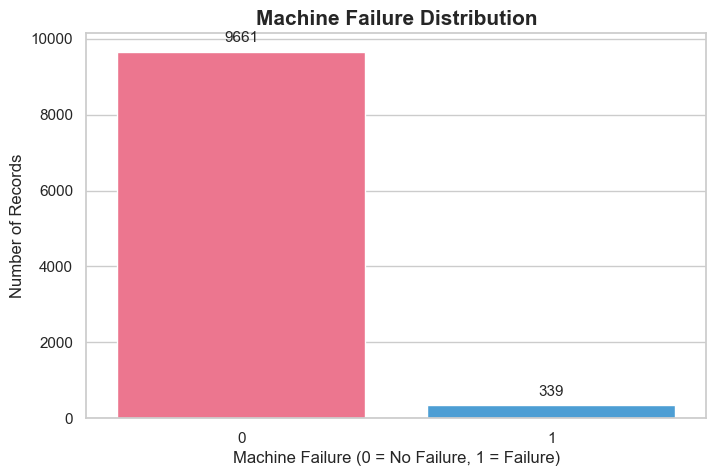

In [19]:
# Plot target distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Machine failure",
    hue="Machine failure",
    palette=["#FF6384", "#36A2EB"],
    legend=False
)

# Add count labels above bars

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5, fontsize=11)

plt.title("Machine Failure Distribution", fontsize=15, fontweight="bold")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")

plt.show()

### Class Imbalance Observation

The dataset contains significantly more records without machine failure
than records with machine failure.

Approximately 96.61% of the records belong to the No Failure class,
while only 3.39% belong to the Failure class.

This indicates a highly imbalanced dataset.

If a model predicts No Failure for every record, it can still achieve
96.61% accuracy, but it will fail to identify actual machine failures.

Therefore, accuracy alone will not be sufficient for evaluating
our models.

In later phases, we will focus on Recall, Precision, F1-score,
PR-AUC and confusion matrices.

We will also consider class imbalance during model training.

## Univariate analysis

### Product type distribution

Univariate analysis means analyzing one variable at a time.

First, we analyze the distribution of the product Type column
to understand the number of records in each category.

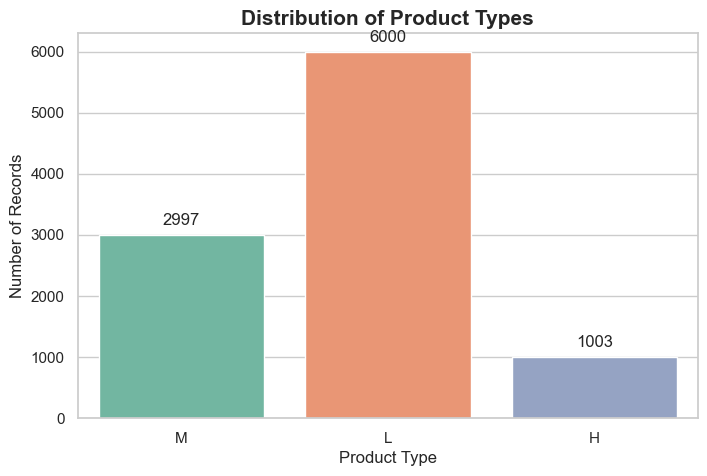

In [20]:
# Visualize product type distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Type",
    hue="Type",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5)

plt.title("Distribution of Product Types", fontsize=15, fontweight="bold")
plt.xlabel("Product Type")
plt.ylabel("Number of Records")

plt.show()

### Sensor distribution using histograms

### Numerical Feature Distribution

We use histograms to understand the distribution of sensor measurements.

The five numerical features are:
1. Air temperature
2. Process temperature
3. Rotational speed
4. Torque
5. Tool wear

Histograms help us understand the spread, frequency and shape
of the values.

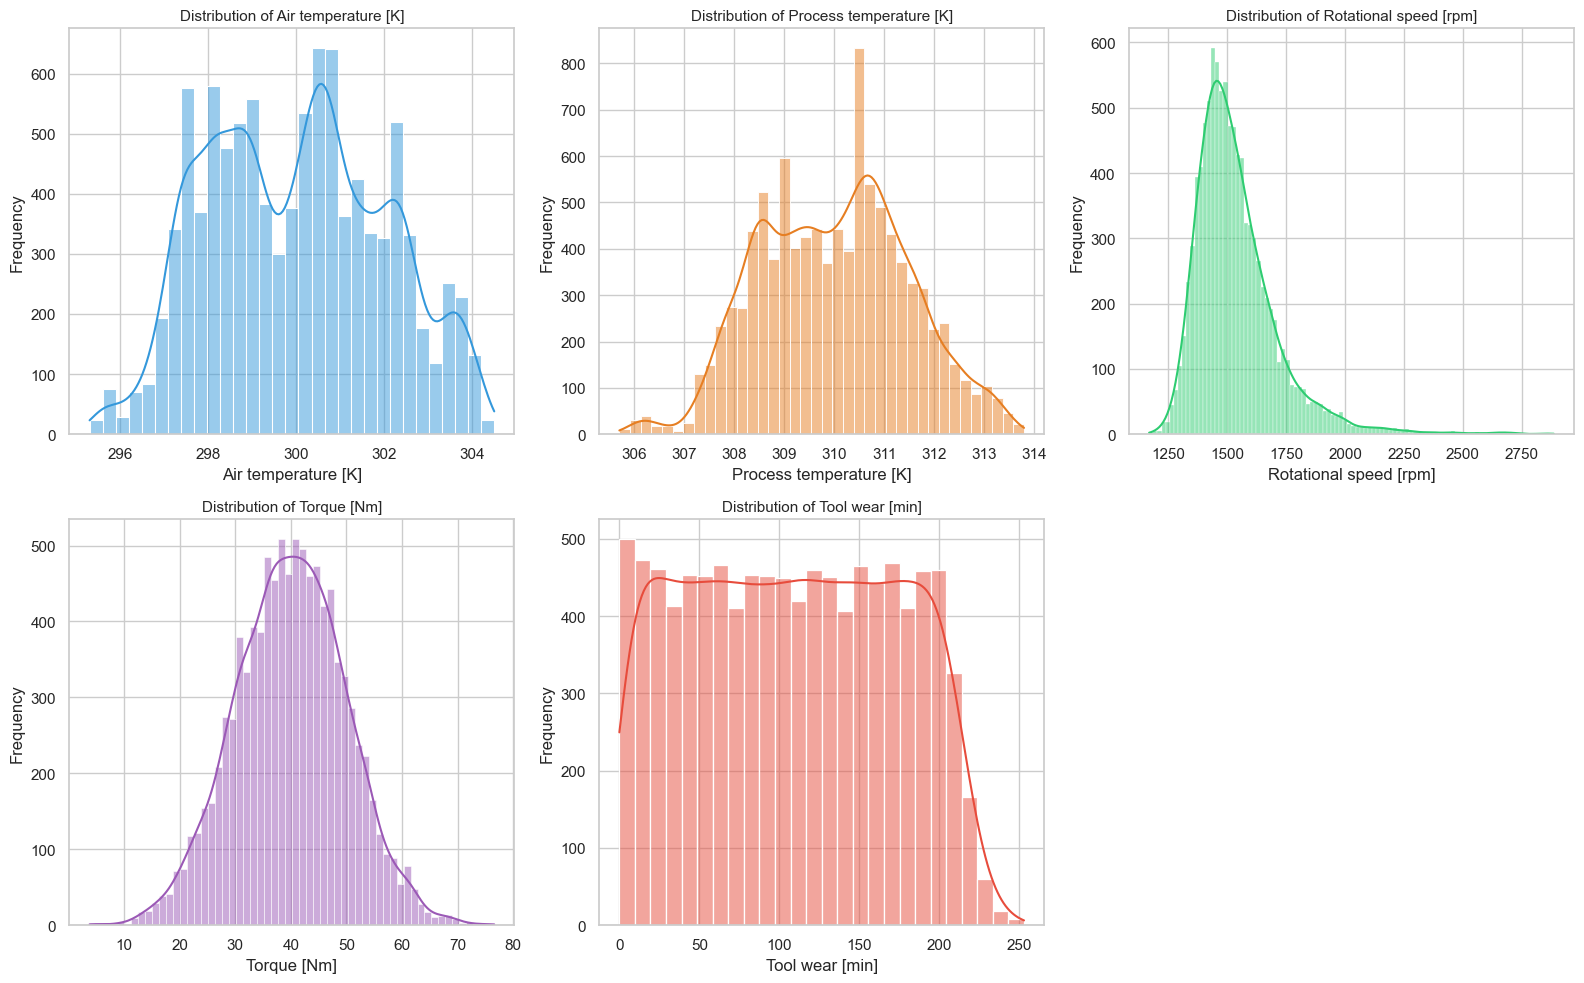

In [21]:
# Plot histograms for numerical sensor columns

plt.figure(figsize=(16, 10))

colors = ["#3498DB", "#E67E22", "#2ECC71", "#9B59B6", "#E74C3C"]

for i, column in enumerate(sensor_columns):

    plt.subplot(2, 3, i + 1)

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        color=colors[i]
    )

    plt.title(f"Distribution of {column}", fontsize=11)
    plt.xlabel(column)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

##  Outlier Analysis

Outliers are values that are unusually far from the majority
of observations.

We use boxplots to identify potential outliers in the sensor readings.

However, an outlier is not automatically an incorrect value.
In industrial data, unusual readings may represent genuine
machine operating conditions.

We will inspect them before deciding whether any treatment is needed.

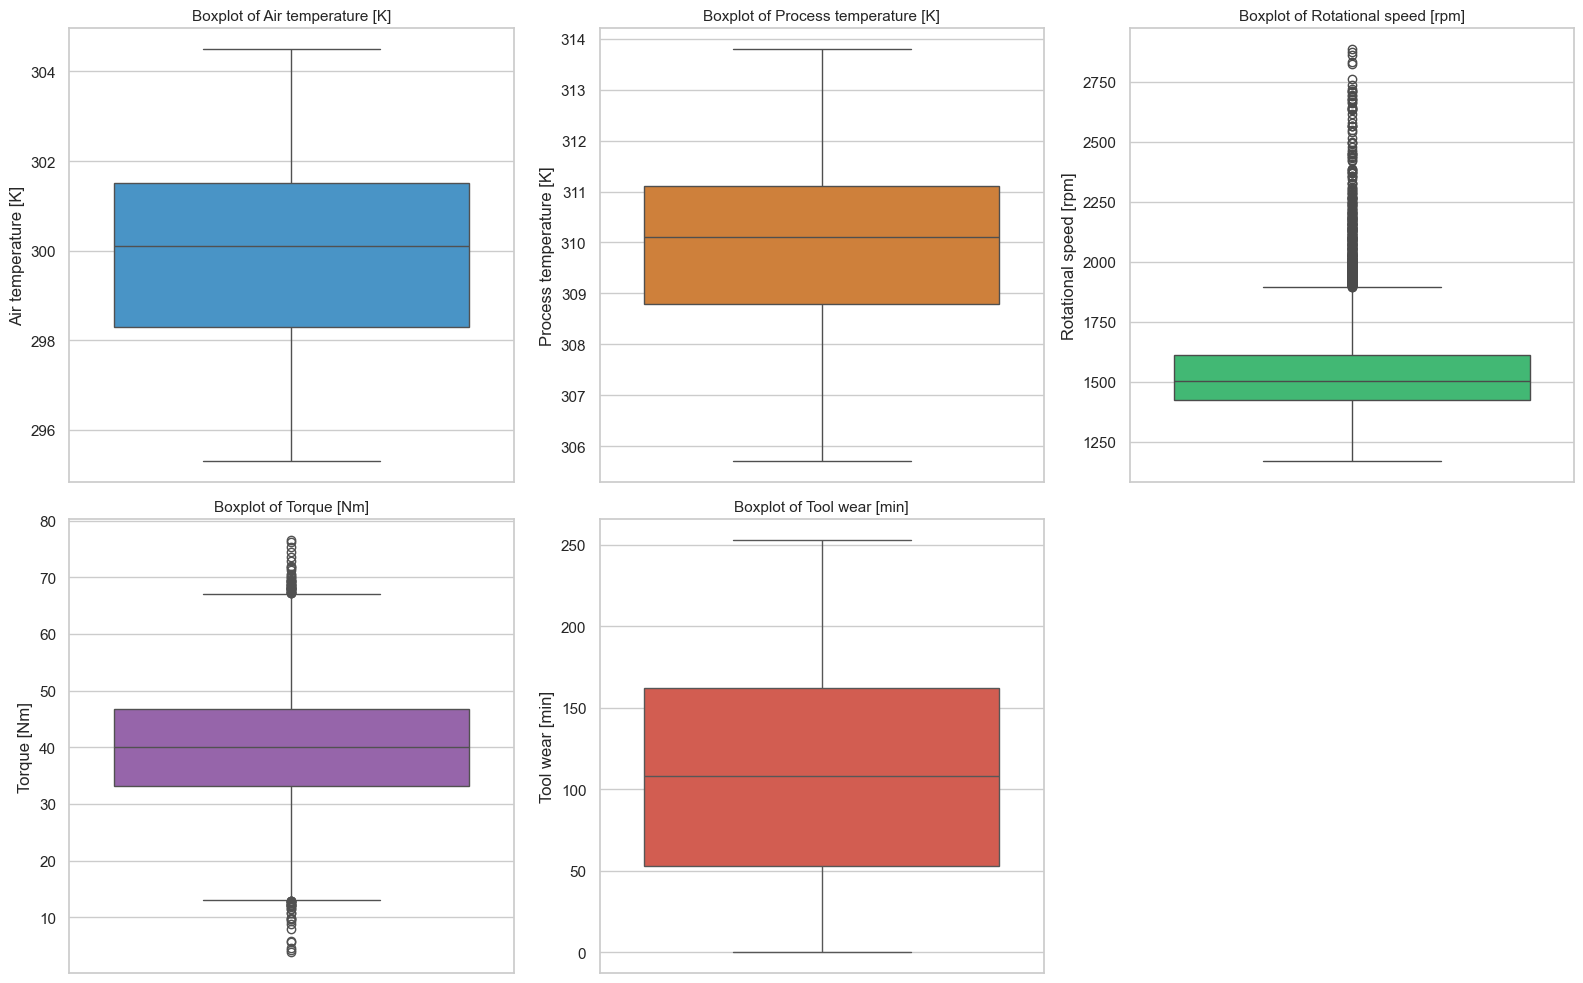

In [22]:
# Visualize outliers using boxplots

plt.figure(figsize=(16, 10))

for i, column in enumerate(sensor_columns):

    plt.subplot(2, 3, i + 1)

    sns.boxplot(
        data=df,
        y=column,
        color=colors[i]
    )

    plt.title(f"Boxplot of {column}", fontsize=11)
    plt.ylabel(column)

plt.tight_layout()
plt.show()

### Count statistical outliers using IQR

In [23]:
# Identify statistical outliers using IQR method

outlier_results = []

for column in sensor_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ).sum()

    outlier_results.append({
        "Feature": column,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Lower Limit,Upper Limit,Outlier Count
0,Air temperature [K],293.50,306.30,0
1,Process temperature [K],305.35,314.55,0
2,Rotational speed [rpm],1139.50,1895.50,418
3,Torque [Nm],12.80,67.20,69
4,Tool wear [min],-110.50,325.50,0


Important observation: Rotational speed and torque contain statistical outliers according to the IQR method. We will not automatically remove them because they may represent genuine operating conditions. We should retain them unless further evidence shows they are incorrect.

##  Bivariate Analysis

Bivariate analysis means studying the relationship between two variables.

First, we investigate whether the machine failure rate differs
across product types.

This helps us understand whether failure occurrence varies
between L, M and H product categories.

### Failure rate by product type

In [24]:
# Calculate failure percentage for each product type

failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .mean()
    .reset_index()
)

failure_by_type["Machine failure"] = (
    failure_by_type["Machine failure"] * 100
)

display(failure_by_type.round(2))

,Type,Machine failure
0,H,2.09
1,L,3.92
2,M,2.77


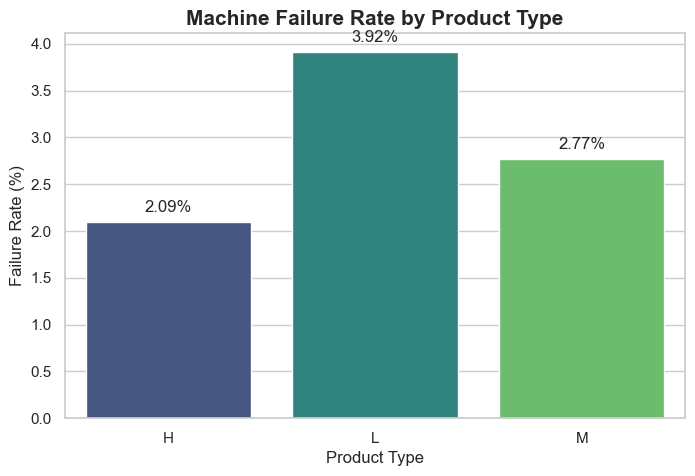

In [25]:
# Plot failure percentage by product type

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=failure_by_type,
    x="Type",
    y="Machine failure",
    hue="Type",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5
    )

plt.title("Machine Failure Rate by Product Type",
          fontsize=15, fontweight="bold")

plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

Observation: In this dataset, the L category has a higher observed failure percentage than M and H. This is an association in the supplied data, not proof that product type causes machine failure.

### Sensor Measurements vs Machine Failure

We compare the sensor measurements for two groups:

- Machine failure = 0
- Machine failure = 1

Boxplots help us observe whether the distributions of sensor
measurements differ between the two target classes.

This may help us identify operating patterns associated
with machine failure.

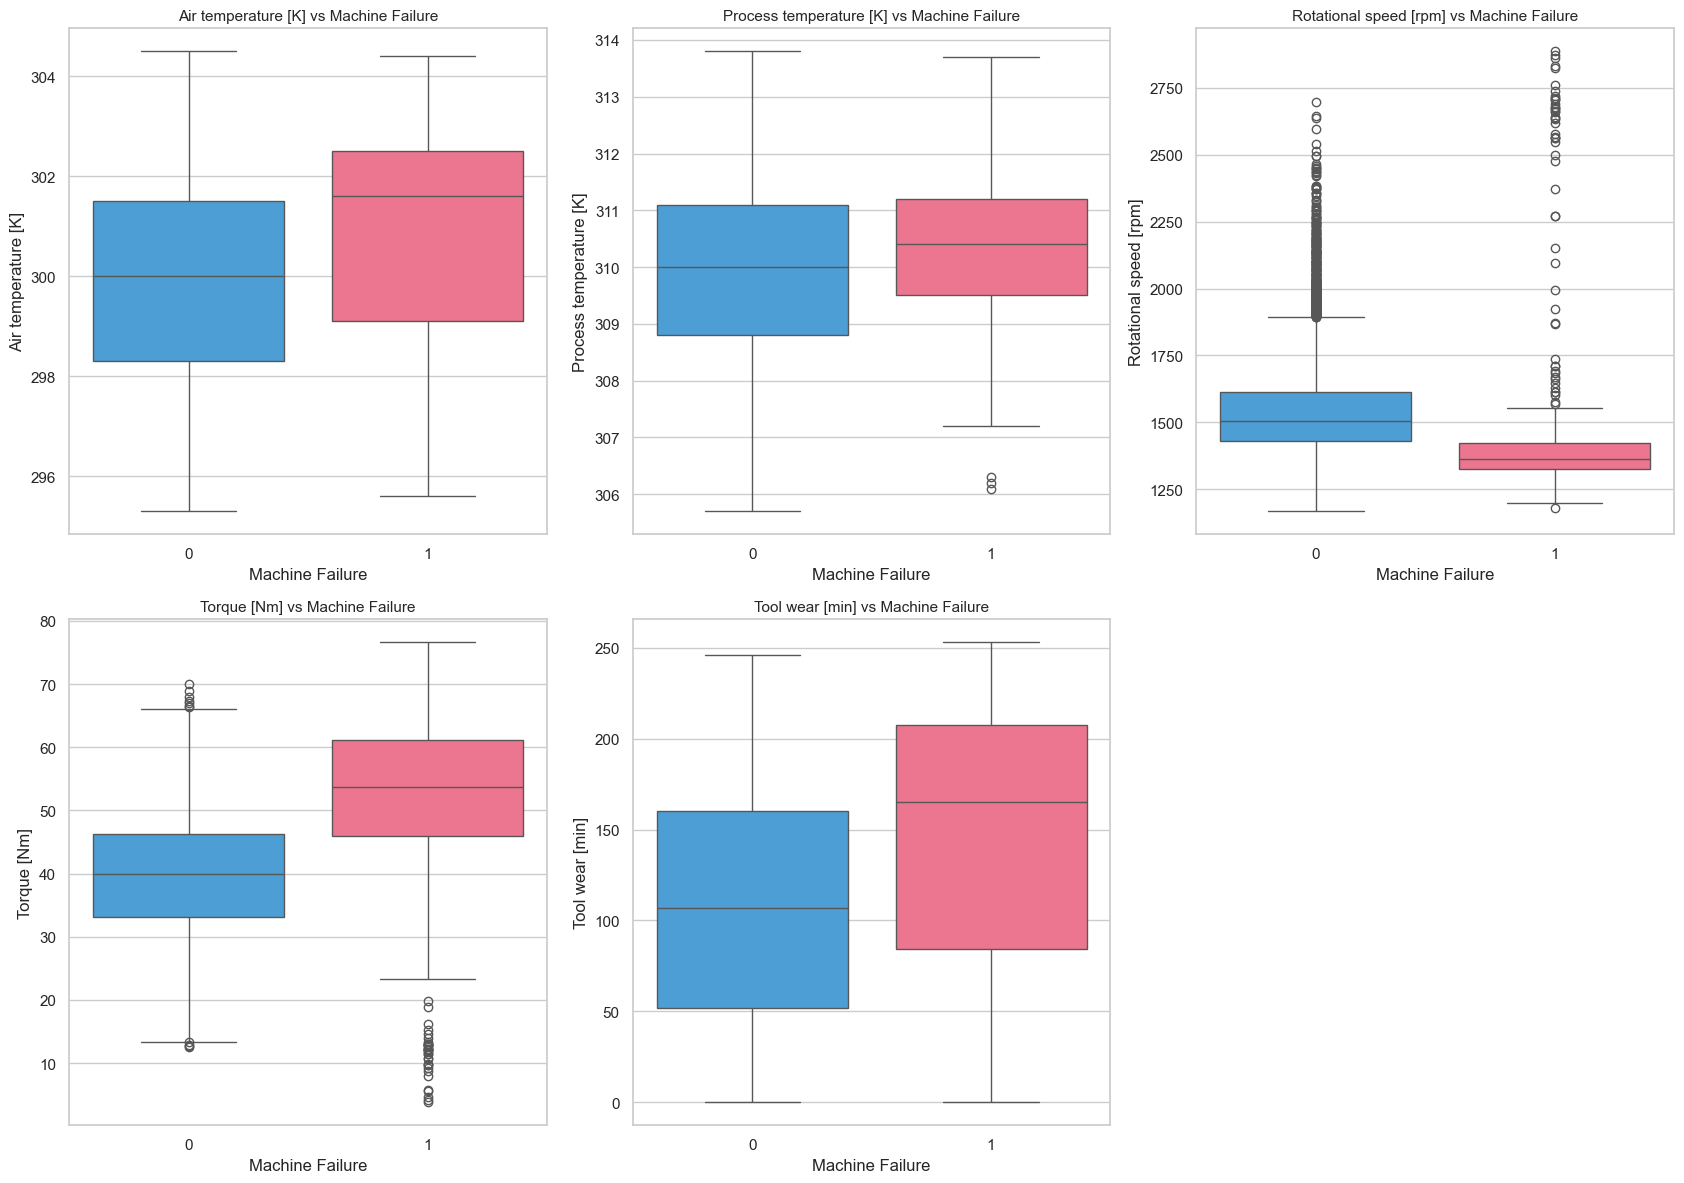

In [26]:
# Compare numerical features against machine failure

plt.figure(figsize=(17, 12))

for i, column in enumerate(sensor_columns):

    plt.subplot(2, 3, i + 1)

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        hue="Machine failure",
        palette=["#36A2EB", "#FF6384"],
        legend=False
    )

    plt.title(f"{column} vs Machine Failure", fontsize=11)
    plt.xlabel("Machine Failure")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

### Quantifying the differences between the failure and no-failure groups

The boxplots are a visual check. To answer *which operating parameters are
associated with failure* with numbers, we compare group medians and the observed
failure rate across quantile bins of each sensor.

In [27]:
group_medians = df.groupby("Machine failure")[sensor_columns].median().T
group_medians.columns = ["Median (No Failure)", "Median (Failure)"]
group_medians["Difference"] = group_medians["Median (Failure)"] - group_medians["Median (No Failure)"]

display(group_medians.round(2))

# Observed failure rate (%) in five equal-sized bins of each sensor
for column in sensor_columns:
    rate_by_bin = (
        df.groupby(pd.qcut(df[column], 5, duplicates="drop"), observed=True)["Machine failure"]
        .mean() * 100
    ).round(2)
    print(f"\nFailure rate (%) by quintile of {column}:")
    print(rate_by_bin.to_string())

,Median (No Failure),Median (Failure),Difference
Air temperature [K],300.0,301.6,1.6
Process temperature [K],310.0,310.4,0.4
Rotational speed [rpm],1507.0,1365.0,-142.0
Torque [Nm],39.9,53.7,13.8
Tool wear [min],107.0,165.0,58.0



Failure rate (%) by quintile of Air temperature [K]:
Air temperature [K]
(295.29900000000004, 298.1]    2.15
(298.1, 299.2]                 2.52
(299.2, 300.6]                 1.96
(300.6, 301.9]                 3.20
(301.9, 304.5]                 7.23

Failure rate (%) by quintile of Process temperature [K]:
Process temperature [K]
(305.699, 308.6]    2.49
(308.6, 309.6]      1.71
(309.6, 310.5]      4.78
(310.5, 311.3]      4.27
(311.3, 313.8]      3.90

Failure rate (%) by quintile of Rotational speed [rpm]:
Rotational speed [rpm]
(1167.999, 1405.0]    12.16
(1405.0, 1470.0]       1.44
(1470.0, 1541.0]       0.60
(1541.0, 1644.0]       0.45
(1644.0, 2886.0]       2.26

Failure rate (%) by quintile of Torque [Nm]:
Torque [Nm]
(3.799, 31.4]     2.35
(31.4, 37.5]      0.45
(37.5, 42.7]      0.59
(42.7, 48.3]      2.17
(48.3, 76.6]     11.50

Failure rate (%) by quintile of Tool wear [min]:
Tool wear [min]
(-0.001, 42.0]    2.37
(42.0, 86.0]      2.09
(86.0, 130.0]     2.33
(130.0, 174

### What we found: which sensors are linked to failure

| Sensor | Normal machines (median) | Failed machines (median) | What it means |
|---|---|---|---|
| Torque | 39.9 Nm | 53.7 Nm | Failed machines work under **more load** |
| Rotational speed | 1507 rpm | 1365 rpm | Failed machines often run **slower** |
| Tool wear | 107 min | 165 min | Failed machines have **more worn tools** |
| Air temperature | 300.0 K | 301.6 K | Slightly hotter |
| Process temperature | 310.0 K | 310.4 K | Almost no difference |

- When torque is very high (above about 48 Nm), about **11.5%** of records fail.
  The overall average is only 3.4%.
- When speed is very low (below about 1405 rpm), about **12.2%** fail.
- When tool wear is very high (above about 174 min), about **8.1%** fail.
- Temperature matters much less.



### Correlation heatmap

We use a correlation heatmap to understand the relationships
between numerical sensor measurements and the target variable.

Correlation values range from -1 to +1.

- Positive correlation: two variables tend to increase together.
- Negative correlation: one variable tends to decrease as the other increases.
- Near zero: little linear relationship is observed.

The heatmap helps us identify possible relationships between
machine operating measurements.

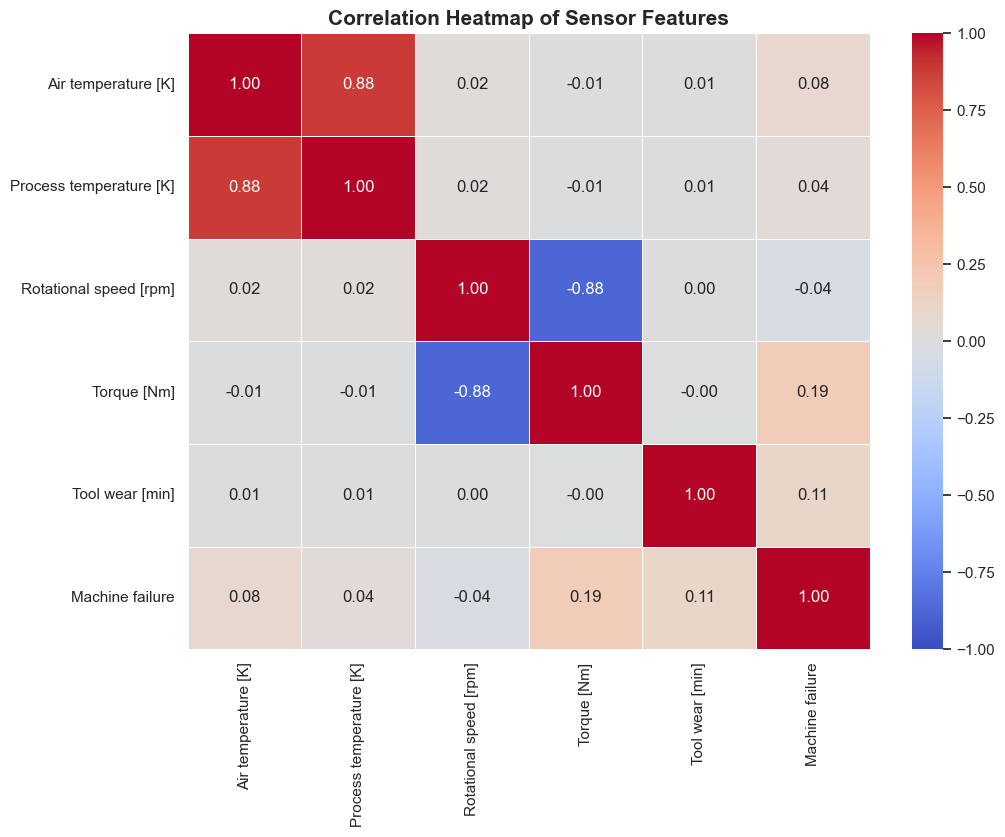

In [28]:
# Select sensor columns and target

correlation_columns = sensor_columns + ["Machine failure"]

# Calculate correlation

correlation_matrix = df[correlation_columns].corr()

# Plot heatmap

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Sensor Features",
          fontsize=15, fontweight="bold")

plt.show()

### What the heatmap tells us

- **Air temperature and process temperature move together** (correlation 0.88).
  When one goes up, the other goes up too.
- **Speed and torque move in opposite directions** (correlation −0.88). When
  speed goes up, torque goes down.
- **No single sensor has a strong straight-line link to failure.** The highest
  is torque, at only 0.19.

**Why this matters:** the earlier analysis showed that failure risk jumps
sharply only at *extreme* values, for example very low or very high speed. A
correlation number only measures straight-line relationships, so it misses
these patterns. This is why tree-based models (Random Forest) and the ANN can
do better than Logistic Regression.

### Scatter plot: rotational speed vs torque

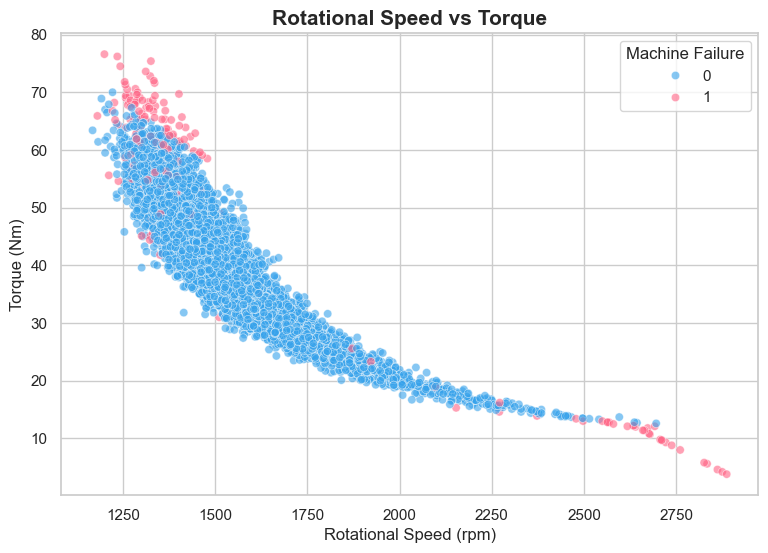

In [29]:
# Relationship between rotational speed and torque

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: "#36A2EB", 1: "#FF6384"},
    alpha=0.6
)

plt.title("Rotational Speed vs Torque",
          fontsize=15, fontweight="bold")

plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")

plt.legend(title="Machine Failure")
plt.show()

### What the scatter plot shows

Failures (pink dots) are not spread everywhere. They gather in **two corners**:

1. **Low speed and high torque.** The machine is working very hard. Out of 538
   records with speed below 1400 rpm and torque above 55 Nm, **24.3% failed**,
   about 7 times the normal rate.
2. **Very high speed.** Out of 226 records above 2000 rpm, **14.6% failed**.


### Feature selection and data preparation

Before preparing the input features, we must identify columns
that should not be used by the Machine Learning models.

### Identifier Columns
- UDI
- Product ID

These columns identify records or products. They are not the
operating measurements that we want the model to learn from.

### Data Leakage Columns
- TWF
- HDF
- PWF
- OSF
- RNF

These columns represent failure-mode indicators.

They are not permitted as input predictors because they contain
information directly related to machine failure.

Using them could give the model information that would not be
appropriate as predictive input.

Therefore, we will exclude all identifier and failure-mode
indicator columns from the model features.

In [30]:
# Define identifier columns

identifier_columns = [
    "UDI",
    "Product ID"
]

# Define leakage columns

leakage_columns = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

# Display columns to be excluded

print("Identifier Columns:")
print(identifier_columns)

print("\nLeakage Columns:")
print(leakage_columns)

Identifier Columns:
['UDI', 'Product ID']

Leakage Columns:
['TWF', 'HDF', 'PWF', 'OSF', 'RNF']


### Feature engineering

We add three features. Each is built from the permitted sensor readings of the
**same record**, and each has a physical meaning in machining:

| New feature | Formula | Why it is useful |
|---|---|---|
| Temperature difference [K] | Process temperature − Air temperature | A small difference means poor heat dissipation |
| Power [W] | Torque × Rotational speed × 2π / 60 | Mechanical power; failures occur when power is too low or too high |
| Strain [min·Nm] | Tool wear × Torque | Combined load on a worn tool (overstrain) |

**Leakage check:** these are fixed, row-wise arithmetic transformations. They do
not learn any parameters from the data and do not use the target or the
failure-mode columns, so creating them before the split cannot leak information
from the validation or test sets. Scaling is still fitted on the training set only.

In [31]:
df["Temperature difference [K]"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Power [W]"] = df["Torque [Nm]"] * df["Rotational speed [rpm]"] * 2 * np.pi / 60
df["Strain [min*Nm]"] = df["Tool wear [min]"] * df["Torque [Nm]"]

engineered_features = [
    "Temperature difference [K]",
    "Power [W]",
    "Strain [min*Nm]"
]

display(df[engineered_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Temperature difference [K],10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10
Power [W],10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92
Strain [min*Nm],10000.0,4314.66,2826.57,0.00,1963.65,4012.95,6279.0,16497.00


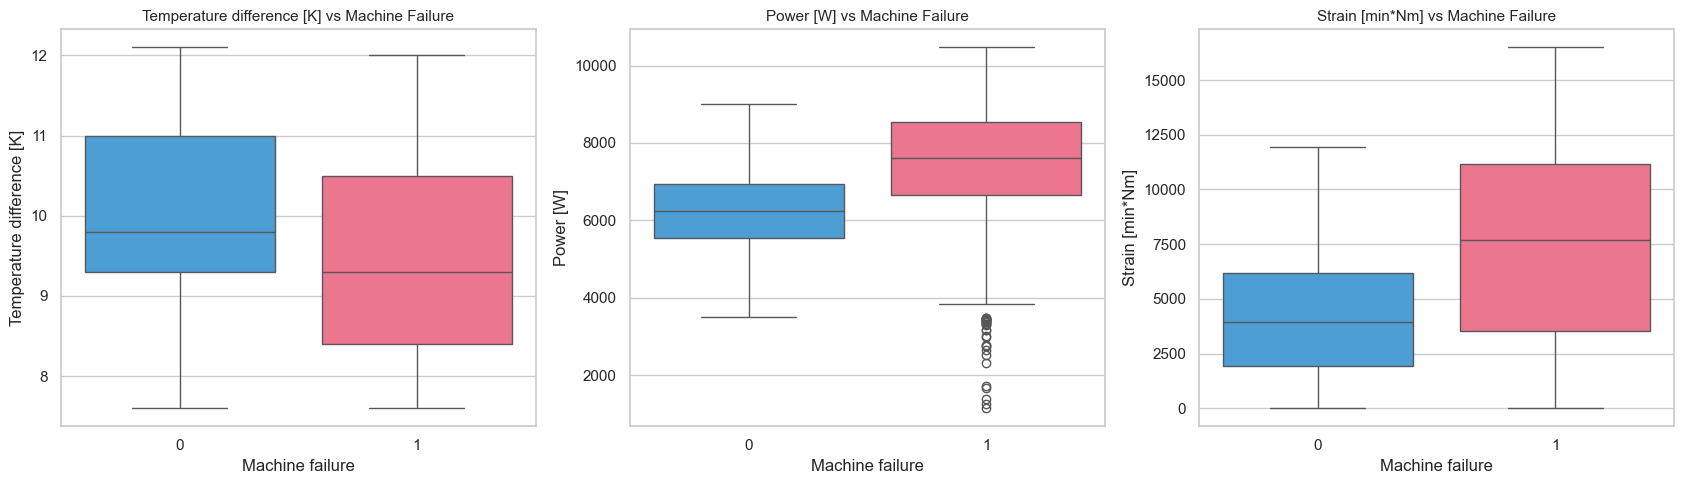


Failure rate (%) by decile of Temperature difference [K]:
Temperature difference [K]
(7.598999999999999, 8.8]    11.85
(8.8, 9.1]                   2.27
(9.1, 9.4]                   2.43
(9.4, 9.6]                   2.75
(9.6, 9.8]                   1.83
(9.8, 10.4]                  2.20
(10.4, 10.8]                 2.16
(10.8, 11.1]                 2.72
(11.1, 11.3]                 2.35
(11.3, 12.1]                 1.72

Failure rate (%) by decile of Power [W]:
Power [W]
(1148.44, 4914.985]       4.0
(4914.985, 5383.01]       0.6
(5383.01, 5717.834]       0.5
(5717.834, 6007.911]      0.8
(6007.911, 6271.027]      1.2
(6271.027, 6546.606]      0.9
(6546.606, 6833.233]      2.4
(6833.233, 7176.204]      2.6
(7176.204, 7640.576]      4.0
(7640.576, 10469.923]    16.9

Failure rate (%) by decile of Strain [min*Nm]:
Strain [min*Nm]
(-0.001, 731.94]       2.6
(731.94, 1552.94]      2.7
(1552.94, 2383.6]      1.6
(2383.6, 3211.52]      1.1
(3211.52, 4012.95]     1.6
(4012.95, 4892.4]      

In [32]:
# Do the engineered features separate failures from non-failures?

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, column in zip(axes, engineered_features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        hue="Machine failure",
        palette=["#36A2EB", "#FF6384"],
        legend=False,
        ax=ax
    )
    ax.set_title(f"{column} vs Machine Failure", fontsize=11)

plt.tight_layout()
plt.show()

for column in engineered_features:
    rate_by_bin = (
        df.groupby(pd.qcut(df[column], 10, duplicates="drop"), observed=True)["Machine failure"]
        .mean() * 100
    ).round(2)
    print(f"\nFailure rate (%) by decile of {column}:")
    print(rate_by_bin.to_string())

### Do the new features help?

Yes. All three new features show clear danger zones:

- **Power:** risk is high at both ends. When power is very high (above about
  7,640 W), **16.9%** fail. When it is very low, 4.0% fail. In the normal middle
  range, only about 1% fail.
- **Strain (tool wear × torque):** in the top 10% of strain values, **15.4%**
  fail, compared with about 1–3% elsewhere.
- **Temperature difference:** when the gap between process and air temperature
  is small (8.8 K or less), **11.9%** fail. The machine cannot cool itself well.

**Result:** these features improved the Random Forest a lot. Its validation
PR-AUC rose from 0.69 (without them) to 0.87 (with them).

### Prepare features and target

Now we separate the dataset into input features and the target variable.

### Input Features (X)
The model will use the following nine features:

1. Type
2. Air temperature [K]
3. Process temperature [K]
4. Rotational speed [rpm]
5. Torque [Nm]
6. Tool wear [min]
7. Temperature difference [K] (engineered)
8. Power [W] (engineered)
9. Strain [min*Nm] (engineered)

### Target Variable (y)
Machine failure

- 0 – No failure
- 1 – Failure

Identifier columns and failure-mode indicators are excluded.

Encoding and scaling will be performed in Phase 2 after
splitting the dataset into training, validation and test sets.

In [33]:
# Define target column

target_column = "Machine failure"

# Combine identifier and leakage columns

columns_to_drop = (
    identifier_columns + leakage_columns
)

# Prepare input features

X = df.drop(
    columns=columns_to_drop + [target_column]
)

# Prepare target variable

y = df[target_column].copy()

# Display feature and target information

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Feature Columns:")

print(X.columns.tolist())

print("\nTarget Distribution:")

print(y.value_counts())

Input Features Shape: (10000, 9)
Target Shape: (10000,)

Input Feature Columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Power [W]', 'Strain [min*Nm]']

Target Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


## Phase 1 – Summary

### About the data
- 10,000 records, 14 columns. The target is `Machine failure` (0 = no, 1 = yes).

### Data quality
- **Clean:** no missing values, no duplicate rows, no wrong categories, no
  negative readings.
- **One real problem found:** 27 records have labels that do not agree.
  - 9 records are marked as failures, but no failure type is recorded.
  - 18 records have a random failure (RNF) recorded, but are marked as "no failure".
  - We kept the labels as given and noted this as a limitation.
- **Outliers:** speed has 418 and torque has 69. We **kept** them, because
  they are real operating conditions and many failures happen there.

### What we learned from EDA
- Only **3.39%** of records are failures, so the data is very imbalanced and
  accuracy alone would be misleading.
- Failure is most linked to **high torque, low speed and high tool wear**.
- Product type L fails slightly more often (3.92%) than M (2.77%) and H (2.09%).

### Data preparation
- Removed the ID columns (UDI, Product ID) and the 5 failure-type columns
  (to prevent leakage).
- Added 3 new features: temperature difference, power and strain.
- The final input has **9 features**.

# Phase 2 – Machine Learning and ANN Development

In this phase, we develop different Machine Learning and Deep Learning
models to predict machine failure.

We will use three models:

1. Logistic Regression
2. Random Forest
3. Artificial Neural Network (ANN)

Before model training, we will split the dataset into training,
validation and testing sets.

We will apply One-Hot Encoding to categorical features,
StandardScaler to numerical features, and class weighting
to handle the imbalanced target variable.

Finally, we will perform basic hyperparameter tuning
to improve model performance.

### Import required libraries

In [34]:
# Import additional libraries for modelling
# (pandas, numpy, matplotlib and seaborn were imported in Phase 1)

import random

# Data splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Class imbalance
from sklearn.utils.class_weight import compute_class_weight

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Statistical testing (Phase 4)
from scipy import stats

# Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.22.0-rc0


### Setting Random Seed

We set a random seed to make our experiments more reproducible.


In [35]:
# Set random seed

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# Make TensorFlow operations deterministic so that re-running the notebook
# gives the same ANN results
tf.config.experimental.enable_op_determinism()

print("Random seed set to:", RANDOM_STATE)

Random seed set to: 42


### Splitting the Dataset

We divide the dataset into three parts:

1. Training Set – 70%
   Used to train the models.

2. Validation Set – 15%
   Used to monitor model performance and make model decisions.

3. Testing Set – 15%
   Used for final evaluation on unseen data.

We use stratified splitting to maintain approximately the same
proportion of failure and no-failure records in all three sets.

This is important because our target variable is highly imbalanced.

In [36]:
# First split: 70% training and 30% temporary data

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Second split: Divide temporary data equally
# 15% validation and 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training Set Shape:", X_train.shape)
print("Validation Set Shape:", X_val.shape)
print("Testing Set Shape:", X_test.shape)

Training Set Shape: (7000, 9)
Validation Set Shape: (1500, 9)
Testing Set Shape: (1500, 9)


### Check target distribution in each split

In [37]:
# Check target distribution in training, validation and test sets

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nValidation Target Distribution:")
print(y_val.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Target Distribution:
Machine failure
0    6763
1     237
Name: count, dtype: int64

Validation Target Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64

Testing Target Distribution:
Machine failure
0    1449
1      51
Name: count, dtype: int64


### Why this split strategy, and its limitations

**Why a random stratified split is acceptable here:**
- Every `UDI` and `Product ID` is unique, so the same product cannot appear in
  both the training and the test set (no group leakage).
- The doc states that the dataset is **not a per-machine time series**, so there
  is no time order that a random split would violate.
- Stratification keeps the 3.4% failure rate equal in all three sets
  (237 / 51 / 51 failures), which matters when there are so few failures.

**Remaining limitations:**
- Only 51 failures in the validation and test sets, so each missed failure
  changes recall by about 2 percentage points. The metrics have wide uncertainty.
- The validation set is used three times: for ANN early stopping, for model
  comparison, and for threshold and cost selection. Validation scores, especially
  the ANN's, are therefore slightly optimistic. The untouched test set gives the
  unbiased estimate.
- In a real plant, the model should be validated with a **time-based** split
  (train on past months, test on later months) and grouped by machine.

### Identify numerical and categorical features

Our prepared dataset contains nine input features.

Categorical Feature:
- Type

Numerical Features:
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]
- Temperature difference [K] (engineered)
- Power [W] (engineered)
- Strain [min*Nm] (engineered)

We need different preprocessing methods for numerical and
categorical features.

In [38]:
# Identify categorical columns

categorical_features = ["Type"]

# Identify numerical columns (original sensors + engineered features)

numerical_features = sensor_columns + engineered_features

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Type']

Numerical Features:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Power [W]', 'Strain [min*Nm]']


### One-Hot Encoding and StandardScaler

### Feature Preprocessing

Machine Learning models work with numerical values.

Therefore, we need to convert categorical values into numerical
representations and scale numerical features.

### One-Hot Encoding
The Type column contains three categories: L, M and H.

One-Hot Encoding converts these categories into separate binary
columns.

For example:
- H = [1, 0, 0]
- L = [0, 1, 0]
- M = [0, 0, 1]

### StandardScaler
StandardScaler transforms numerical features so that they have
approximately:
- Mean = 0
- Standard deviation = 1

This helps models such as Logistic Regression and ANN
when features have different numerical ranges.

Important:
We fit the encoder and scaler only on the training data.
The validation and test sets are transformed using the same
training-fitted preprocessing object.

This prevents data leakage.

In [39]:
# Create One-Hot Encoder

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )

except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Create preprocessing object

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", encoder, categorical_features)
    ]
)

print("Preprocessing object created successfully!")

Preprocessing object created successfully!


### Fit preprocessing on training data

In [40]:
# Fit and transform training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation data

X_val_processed = preprocessor.transform(X_val)

# Transform testing data

X_test_processed = preprocessor.transform(X_test)

print("Training Data:", X_train_processed.shape)

print("Validation Data:", X_val_processed.shape)

print("Testing Data:", X_test_processed.shape)

Training Data: (7000, 11)
Validation Data: (1500, 11)
Testing Data: (1500, 11)


### Display encoded feature names

In [41]:
# Get transformed feature names

feature_names = preprocessor.get_feature_names_out()

print("Features after preprocessing:")

for feature in feature_names:
    print(feature)

Features after preprocessing:
num__Air temperature [K]
num__Process temperature [K]
num__Rotational speed [rpm]
num__Torque [Nm]
num__Tool wear [min]
num__Temperature difference [K]
num__Power [W]
num__Strain [min*Nm]
cat__Type_H
cat__Type_L
cat__Type_M


### Check scaled data

In [42]:
# Convert processed data into DataFrame for easy viewing

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

# Display first five processed records

display(X_train_df.head())

,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],num__Temperature difference [K],num__Power [W],num__Strain [min*Nm],cat__Type_H,cat__Type_L,cat__Type_M
0,-1.105779,-1.759415,2.012835,-1.569298,0.334742,-0.392635,-1.346709,-0.412341,0.0,0.0,1.0
1,1.840492,1.547973,-1.055557,1.099287,-0.041084,-1.393563,0.860509,0.371765,0.0,1.0,0.0
2,-1.405400,-1.421926,-0.256554,-0.160045,0.600952,0.708385,-0.260460,0.460547,0.0,1.0,0.0
3,1.790556,1.547973,0.503608,-0.759727,1.806727,-1.293470,-0.702209,1.032232,0.0,0.0,1.0
4,0.442262,1.277982,3.333409,-2.348885,-1.011967,1.008663,-2.413018,-1.268809,1.0,0.0,0.0


### Handling Class Imbalance

Our dataset contains:

- 96.61% No Failure records
- 3.39% Failure records

This means the dataset is highly imbalanced.

If we train a model without considering this imbalance,
it may mostly predict the majority class (No Failure).

To address this problem, we use class weights.

Class weights assign more importance to the minority class
during model training.

We calculate the weights using only the training target values
to avoid using information from validation or test data.

### Calculate class weights

In [43]:
# Calculate class weights using training data only

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")

print(class_weights)

Class Weights:
{np.int64(0): np.float64(0.5175218098477007), np.int64(1): np.float64(14.767932489451477)}


### Visualize class weights

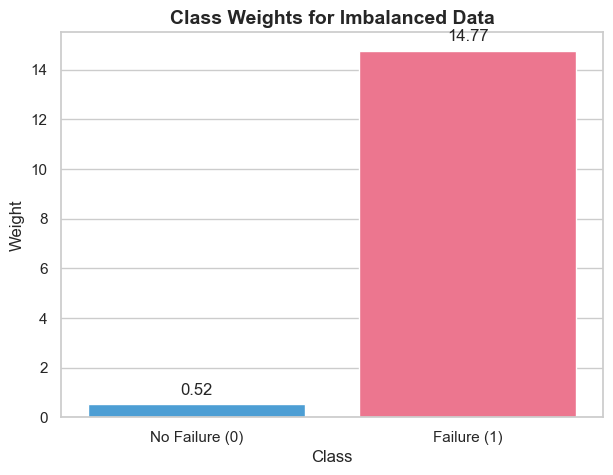

In [44]:
# Create class weight DataFrame

weight_df = pd.DataFrame({
    "Class": ["No Failure (0)", "Failure (1)"],
    "Weight": [
        class_weights[0],
        class_weights[1]
    ]
})

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=weight_df,
    x="Class",
    y="Weight",
    hue="Class",
    palette=["#36A2EB", "#FF6384"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

plt.title("Class Weights for Imbalanced Data",
          fontsize=14, fontweight="bold")

plt.xlabel("Class")
plt.ylabel("Weight")

plt.show()

Observation: The failure class has a higher weight. This encourages the models to pay more attention to failure records during training.

## Model 1 – Logistic Regression

Logistic Regression is a supervised Machine Learning algorithm
used for classification problems.

In our project, it predicts whether a machine will experience
failure or not.

It estimates the probability of machine failure and produces
a binary prediction.

We use Logistic Regression as our baseline model.

We also apply class_weight="balanced" to address class imbalance.

### Train Logistic Regression

In [45]:
# Create Logistic Regression model

lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

# Train the model

lr_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


### Generate Logistic Regression predictions

In [46]:
# Predict probabilities on validation data

lr_val_probabilities = lr_model.predict_proba(
    X_val_processed
)[:, 1]

# Display first ten probabilities

print("First 10 predicted failure probabilities:")

print(lr_val_probabilities[:10])

First 10 predicted failure probabilities:
[0.393066   0.45164548 0.22726043 0.04617628 0.01718662 0.20322134
 0.05833534 0.13288807 0.07312833 0.21455341]


### Basic hyperparameter tuning – Logistic Regression

We tune the regularisation strength `C`: smaller values mean stronger
regularisation. The search uses 3-fold stratified cross-validation on the
**training data only**, with Average Precision (PR-AUC) as the score. The
preprocessing sits inside the pipeline, so the scaler is refitted on each
training fold.

In [47]:
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

lr_param_grid = {"model__C": [0.01, 0.1, 1, 10, 100]}

lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1
)

lr_grid_search.fit(X_train, y_train)

best_lr_model = lr_grid_search.best_estimator_

lr_tuning_results = pd.DataFrame(lr_grid_search.cv_results_)[
    ["param_model__C", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")

print("Best Logistic Regression parameters:", lr_grid_search.best_params_)
print("Best cross-validation PR-AUC:", round(lr_grid_search.best_score_, 4))
display(lr_tuning_results.round(4))

Best Logistic Regression parameters: {'model__C': 0.1}
Best cross-validation PR-AUC: 0.4899


,param_model__C,mean_test_score,std_test_score,rank_test_score
1,0.10,0.4899,0.0271,1
2,1.00,0.4737,0.0316,2
3,10.00,0.4601,0.0296,3
4,100.00,0.4565,0.0298,4
0,0.01,0.4055,0.0220,5


## Model 2 – Random Forest

Random Forest is an ensemble Machine Learning algorithm.

It creates multiple Decision Trees and combines their predictions
to make a final prediction.

Each tree learns patterns from the training data.

The final prediction is based on the combined results of the trees.

Random Forest can capture complex and non-linear relationships
between machine operating measurements and failure.

We use class_weight="balanced_subsample" to address
the imbalanced target variable.

### Train Random Forest

In [48]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train the model

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest training completed!")

Random Forest training completed!


### Generate Random Forest predictions

In [49]:
# Predict probabilities on validation data

rf_val_probabilities = rf_model.predict_proba(
    X_val_processed
)[:, 1]

print("First 10 predicted failure probabilities:")

print(rf_val_probabilities[:10])

First 10 predicted failure probabilities:
[0.00666667 0.         0.00333333 0.         0.         0.
 0.         0.         0.         0.00333333]


## Model 3 – Artificial Neural Network (ANN)

An Artificial Neural Network is a Deep Learning model inspired
by the way biological neurons process information.

An ANN contains layers of connected neurons.

Each neuron receives input values, applies weights and bias,
and passes the result through an activation function.

For our binary classification problem, the ANN learns patterns
from machine operating measurements and predicts the probability
of machine failure.


### Convert data to ANN format

In [50]:
# Convert input data into float32 format for TensorFlow

X_train_ann = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_val_ann = np.asarray(
    X_val_processed,
    dtype=np.float32
)

X_test_ann = np.asarray(
    X_test_processed,
    dtype=np.float32
)

# Convert target values

y_train_ann = np.asarray(y_train, dtype=np.float32)

y_val_ann = np.asarray(y_val, dtype=np.float32)

y_test_ann = np.asarray(y_test, dtype=np.float32)

print("ANN data preparation completed!")

print("Training input shape:", X_train_ann.shape)
print("Validation input shape:", X_val_ann.shape)
print("Testing input shape:", X_test_ann.shape)

ANN data preparation completed!
Training input shape: (7000, 11)
Validation input shape: (1500, 11)
Testing input shape: (1500, 11)


### Build ANN model

In [51]:
# Clear previous Keras model state

tf.keras.backend.clear_session()

# Build ANN model

ann_model = Sequential([

    Input(shape=(X_train_ann.shape[1],)),

    Dense(64, activation="relu"),

    Dropout(0.30),

    Dense(32, activation="relu"),

    Dropout(0.20),

    Dense(1, activation="sigmoid")

])

print("ANN model created successfully!")

ANN model created successfully!


### Compile ANN model

In [52]:
# Compile ANN model

ann_model.compile(

    optimizer=Adam(learning_rate=0.001),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc"),
        tf.keras.metrics.AUC(
            curve="PR",
            name="pr_auc"
        )
    ]

)

print("ANN model compiled successfully!")

ANN model compiled successfully!


### Display ANN architecture

In [53]:
# Display ANN architecture

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

### Callbacks

Callbacks help control the training process.

We use two callbacks:

1. EarlyStopping:
   Stops training when validation loss does not improve for
   several consecutive epochs. It restores the best model weights.

2. ReduceLROnPlateau:
   Reduces the learning rate when validation loss stops improving.

These callbacks help reduce unnecessary training and may
improve training stability.

In [54]:
# Early stopping callback

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Reduce learning rate callback

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=0.00001
)

print("Callbacks created successfully!")

Callbacks created successfully!


### Train ANN

In [55]:
# Train ANN model

history = ann_model.fit(

    X_train_ann,
    y_train_ann,

    validation_data=(
        X_val_ann,
        y_val_ann
    ),

    epochs=50,

    batch_size=32,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=2

)

print("ANN training completed!")
print("Epochs actually run:", len(history.history["loss"]))

Epoch 1/50


219/219 - 3s - 12ms/step - accuracy: 0.6316 - loss: 0.5880 - pr_auc: 0.2191 - precision: 0.0644 - recall: 0.7300 - roc_auc: 0.7620 - val_accuracy: 0.7660 - val_loss: 0.5055 - val_pr_auc: 0.3242 - val_precision: 0.1094 - val_recall: 0.8235 - val_roc_auc: 0.8831 - learning_rate: 0.0010


Epoch 2/50


219/219 - 1s - 2ms/step - accuracy: 0.7616 - loss: 0.4587 - pr_auc: 0.3368 - precision: 0.1066 - recall: 0.8186 - roc_auc: 0.8715 - val_accuracy: 0.8220 - val_loss: 0.4045 - val_pr_auc: 0.4029 - val_precision: 0.1351 - val_recall: 0.7843 - val_roc_auc: 0.9176 - learning_rate: 0.0010


Epoch 3/50


219/219 - 1s - 3ms/step - accuracy: 0.8149 - loss: 0.4044 - pr_auc: 0.3841 - precision: 0.1391 - recall: 0.8608 - roc_auc: 0.9021 - val_accuracy: 0.8300 - val_loss: 0.3836 - val_pr_auc: 0.4480 - val_precision: 0.1458 - val_recall: 0.8235 - val_roc_auc: 0.9252 - learning_rate: 0.0010


... (89 outputs left out)

219/219 - 1s - 3ms/step - accuracy: 0.9217 - loss: 0.1997 - pr_auc: 0.7228 - precision: 0.2913 - recall: 0.9156 - roc_auc: 0.9755 - val_accuracy: 0.9267 - val_loss: 0.1946 - val_pr_auc: 0.7271 - val_precision: 0.2993 - val_recall: 0.8627 - val_roc_auc: 0.9757 - learning_rate: 1.2500e-04


Epoch 49/50


219/219 - 1s - 3ms/step - accuracy: 0.9153 - loss: 0.2142 - pr_auc: 0.6973 - precision: 0.2747 - recall: 0.9156 - roc_auc: 0.9719 - val_accuracy: 0.9233 - val_loss: 0.1982 - val_pr_auc: 0.7298 - val_precision: 0.2895 - val_recall: 0.8627 - val_roc_auc: 0.9762 - learning_rate: 1.2500e-04


ANN training completed!
Epochs actually run: 49


### ANN Training History

After training, we visualize the model's performance
across the training epochs.

Accuracy is not informative here, because predicting "no failure" for every
record already gives 96.6% accuracy. We therefore plot:
1. Training and validation PR-AUC and recall.
2. Training and validation loss.

These graphs help us understand how the model learns
and whether there are signs of overfitting.

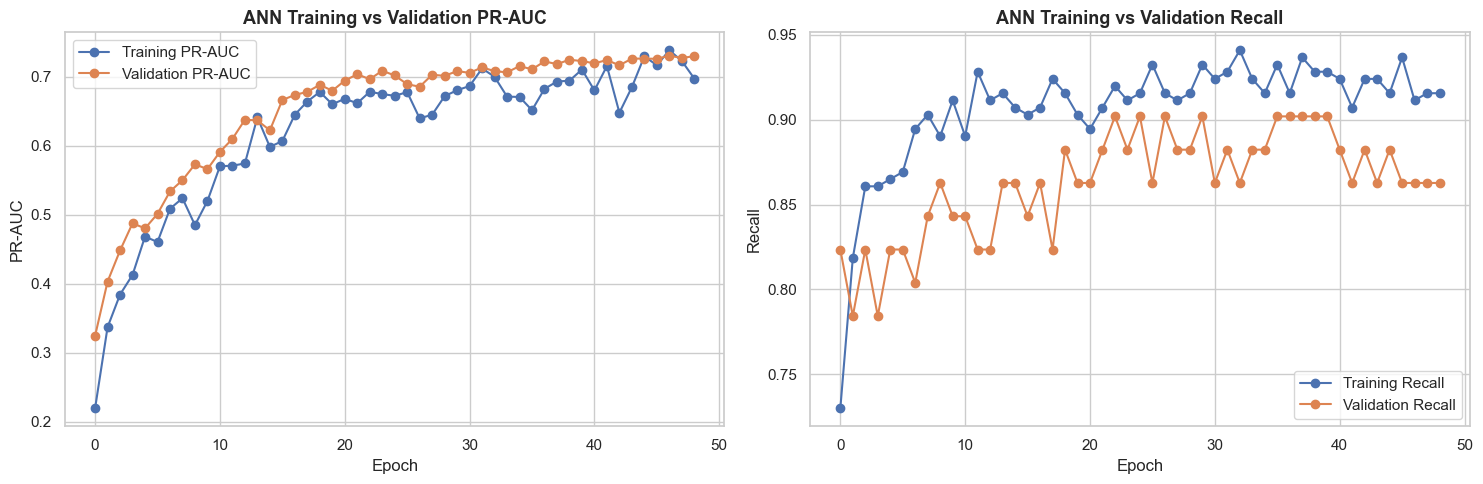

In [56]:
# Plot ANN training vs validation PR-AUC and recall

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, metric, title in zip(axes, ["pr_auc", "recall"], ["PR-AUC", "Recall"]):

    ax.plot(history.history[metric], label=f"Training {title}", marker="o")
    ax.plot(history.history[f"val_{metric}"], label=f"Validation {title}", marker="o")

    ax.set_title(f"ANN Training vs Validation {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### ANN loss graph

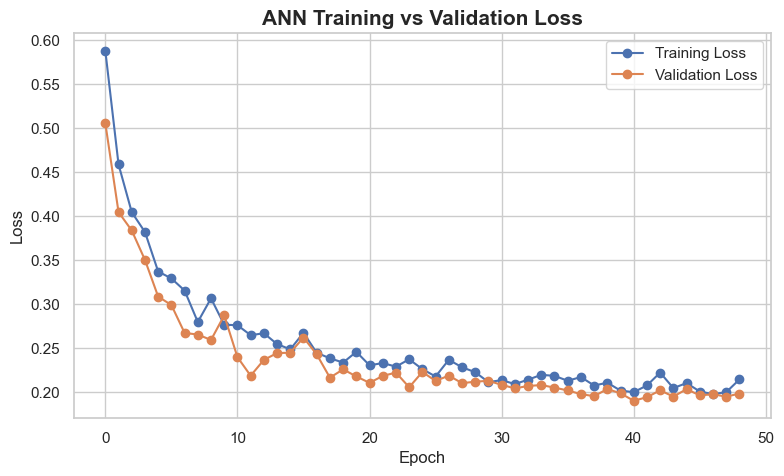

In [57]:
# Plot training and validation loss

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("ANN Training vs Validation Loss",
          fontsize=15, fontweight="bold")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

### What the training graphs show

- The ANN trained for **49 epochs**.
- **Validation loss went down steadily** (from about 0.51 to 0.19) and was
  lowest at epoch 41. Validation PR-AUC went up from about 0.32 to 0.73.
- The validation loss **did not start rising again**, so the model is **not
  overfitting badly**. Dropout and early stopping did their job.


### Generate ANN validation probabilities

In [58]:
# Predict validation probabilities using ANN

ann_val_probabilities = ann_model.predict(
    X_val_ann
).flatten()

print("First 10 ANN predicted probabilities:")

print(ann_val_probabilities[:10])

 1/47 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


First 10 ANN predicted probabilities:
[0.06842579 0.1246798  0.10147204 0.01376447 0.00418607 0.10310464
 0.07672219 0.23986062 0.03791248 0.01627979]


## Basic Hyperparameter Tuning – Random Forest

Hyperparameters are settings that we choose before training
a Machine Learning model.

Tuning means testing different settings to find a better
configuration.

For Random Forest, we will experiment with:

1. max_depth – Maximum depth of each tree.
2. min_samples_leaf – Minimum number of samples required in a leaf node.
   Larger leaves make smoother, less overfitted trees.
3. max_features – Number of features considered at each split.

The number of trees is fixed at 300, because more trees mainly reduce variance
and rarely change the ranking of the other settings.

We use GridSearchCV to test different combinations.

We use Average Precision as the scoring metric because
it summarizes precision-recall performance and is useful
for imbalanced classification.

The search uses only the training data.

### Create Random Forest pipeline for tuning

In [59]:
# Create a pipeline for leakage-safe hyperparameter tuning

rf_pipeline = Pipeline([

    ("preprocessor", preprocessor),

    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))

])

print("Random Forest tuning pipeline created!")

Random Forest tuning pipeline created!


### Define hyperparameter combinations

In [60]:
# Define parameters to test (wider grid than the baseline settings)

param_grid = {

    "model__n_estimators": [300],

    "model__max_depth": [None, 10, 20],

    "model__min_samples_leaf": [1, 3, 5],

    "model__max_features": ["sqrt", None]

}

print("Hyperparameter combinations:")

print(param_grid)

Hyperparameter combinations:
{'model__n_estimators': [300], 'model__max_depth': [None, 10, 20], 'model__min_samples_leaf': [1, 3, 5], 'model__max_features': ['sqrt', None]}


### Run GridSearchCV

In [61]:
# Create stratified cross-validation

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Create GridSearchCV

rf_grid_search = GridSearchCV(

    estimator=rf_pipeline,

    param_grid=param_grid,

    scoring="average_precision",

    cv=cv_strategy,

    n_jobs=-1,

    verbose=1

)

# Perform tuning using training data only

rf_grid_search.fit(
    X_train,
    y_train
)

print("Hyperparameter tuning completed!")

Fitting 3 folds for each of 18 candidates, totalling 54 fits


Hyperparameter tuning completed!


### Display best parameters

In [62]:
# Display best hyperparameters

print("Best Hyperparameters:")

print(rf_grid_search.best_params_)

print("\nBest Cross-Validation Average Precision:")

print(rf_grid_search.best_score_)

Best Hyperparameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 300}

Best Cross-Validation Average Precision:
0.881380892580656


### Compare tuning results

In [63]:
# Convert GridSearchCV results into DataFrame

tuning_results = pd.DataFrame(
    rf_grid_search.cv_results_
)

# Select useful columns

tuning_results = tuning_results[
    [
        "param_model__max_depth",
        "param_model__min_samples_leaf",
        "param_model__max_features",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

# Sort by rank

tuning_results = tuning_results.sort_values(
    by="rank_test_score"
)

display(tuning_results.round(4))

,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_score,std_test_score,rank_test_score
6,10,1,sqrt,0.8814,0.0439,1
12,20,1,sqrt,0.8794,0.0416,2
0,None,1,sqrt,0.8791,0.0414,3
10,10,3,None,0.8774,0.0357,4
4,None,3,None,0.8770,0.0346,5
16,20,3,None,0.8770,0.0346,5
7,10,3,sqrt,0.8765,0.0430,7
1,None,3,sqrt,0.8762,0.0415,8
13,20,3,sqrt,0.8762,0.0415,8
11,10,5,None,0.8745,0.0361,10


### Store tuned Random Forest model

In [64]:
# Store the best tuned Random Forest pipeline

best_rf_model = rf_grid_search.best_estimator_

print("Best tuned Random Forest model is ready!")

Best tuned Random Forest model is ready!


### What tuning found

- **Best settings:** `max_depth = 10`, `max_features = "sqrt"`,
  `min_samples_leaf = 1`. Cross-validation PR-AUC: **0.881**.
- **Default settings** (no depth limit): **0.879**.
- The difference is only **0.002**, and the results already vary by about 0.04
  between folds.

Tuning Logistic Regression (C = 0.1) also gave only a small gain
(0.490 vs 0.474).

## Model Training – Summary

**ANN**
- Layers: 11 inputs → 64 neurons (ReLU) → Dropout 30% → 32 neurons (ReLU) →
  Dropout 20% → 1 output (sigmoid). 2,881 parameters in total.
- Adam optimizer (learning rate 0.001), binary cross-entropy loss, batch size
  32, maximum 50 epochs.
- EarlyStopping stops training when validation loss stops improving.
  ReduceLROnPlateau lowers the learning rate when progress slows.
- Trained for 49 epochs, with no serious overfitting.

**Random Forest**
- Tested 18 setting combinations with 3-fold cross-validation on the training data only.
- The best setting (max_depth = 10) was about as good as the default.

**Logistic Regression**
- Best C = 0.1, cross-validation PR-AUC 0.49. This is much weaker than the tree
  models, because it can only draw straight-line boundaries.

## Phase 3 – Model Evaluation and Reliability Audit

### Import evaluation metrics

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

### Get validation probabilities from all five models

To keep the comparison consistent, every model is wrapped in a function that
takes the **raw** feature table and applies the training-fitted preprocessing
itself. The same functions are used for the training, validation and test sets.

In [66]:
def to_ann_input(X_raw):
    return np.asarray(preprocessor.transform(X_raw), dtype=np.float32)


model_predictors = {
    "Logistic Regression": lambda X_raw: lr_model.predict_proba(preprocessor.transform(X_raw))[:, 1],
    "Tuned Logistic Regression": lambda X_raw: best_lr_model.predict_proba(X_raw)[:, 1],
    "Random Forest": lambda X_raw: rf_model.predict_proba(preprocessor.transform(X_raw))[:, 1],
    "Tuned Random Forest": lambda X_raw: best_rf_model.predict_proba(X_raw)[:, 1],
    "ANN": lambda X_raw: ann_model.predict(to_ann_input(X_raw), verbose=0).flatten()
}

validation_probabilities = {
    name: predict(X_val) for name, predict in model_predictors.items()
}

print("Validation probabilities generated successfully.")

Validation probabilities generated successfully.


### Evaluate all models at the default threshold of 0.5

In [67]:
y_val_actual = np.array(y_val)

results = []

for model_name, probabilities in validation_probabilities.items():

    # Convert probabilities into 0 or 1 predictions
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val_actual, predictions),
        "Precision": precision_score(y_val_actual, predictions, zero_division=0),
        "Recall": recall_score(y_val_actual, predictions, zero_division=0),
        "F1 Score": f1_score(y_val_actual, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val_actual, probabilities),
        "PR-AUC": average_precision_score(y_val_actual, probabilities)
    })

model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.round(4)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8620,0.1695,0.7843,0.2787,0.9048,0.3561
1,Tuned Logistic Regression,0.8647,0.1696,0.7647,0.2776,0.9008,0.3927
2,Random Forest,0.9873,0.9211,0.6863,0.7865,0.9804,0.8744
3,Tuned Random Forest,0.9880,0.9231,0.7059,0.8000,0.9880,0.8634
4,ANN,0.9260,0.3000,0.8824,0.4478,0.9761,0.7279


### Visualize model comparison

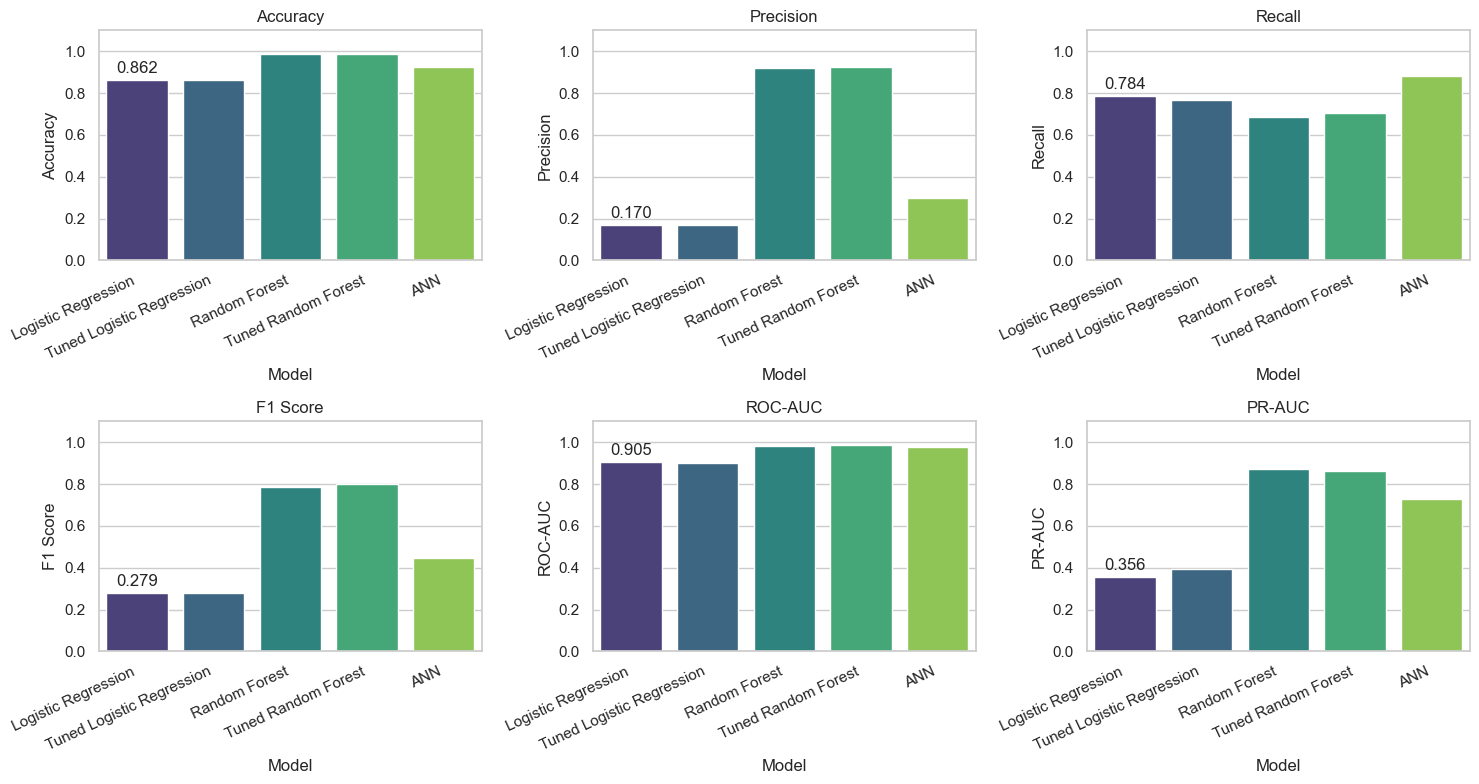

In [68]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"]

plt.figure(figsize=(15, 8))

for i, metric in enumerate(metrics_to_plot, 1):

    plt.subplot(2, 3, i)

    ax = sns.barplot(
        data=model_comparison,
        x="Model",
        y=metric,
        hue="Model",
        palette="viridis",
        legend=False
    )

    ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

    plt.title(metric)
    plt.xticks(rotation=25, ha="right")
    plt.ylim(0, 1.1)

plt.tight_layout()
plt.show()

### Confusion matrices for all models

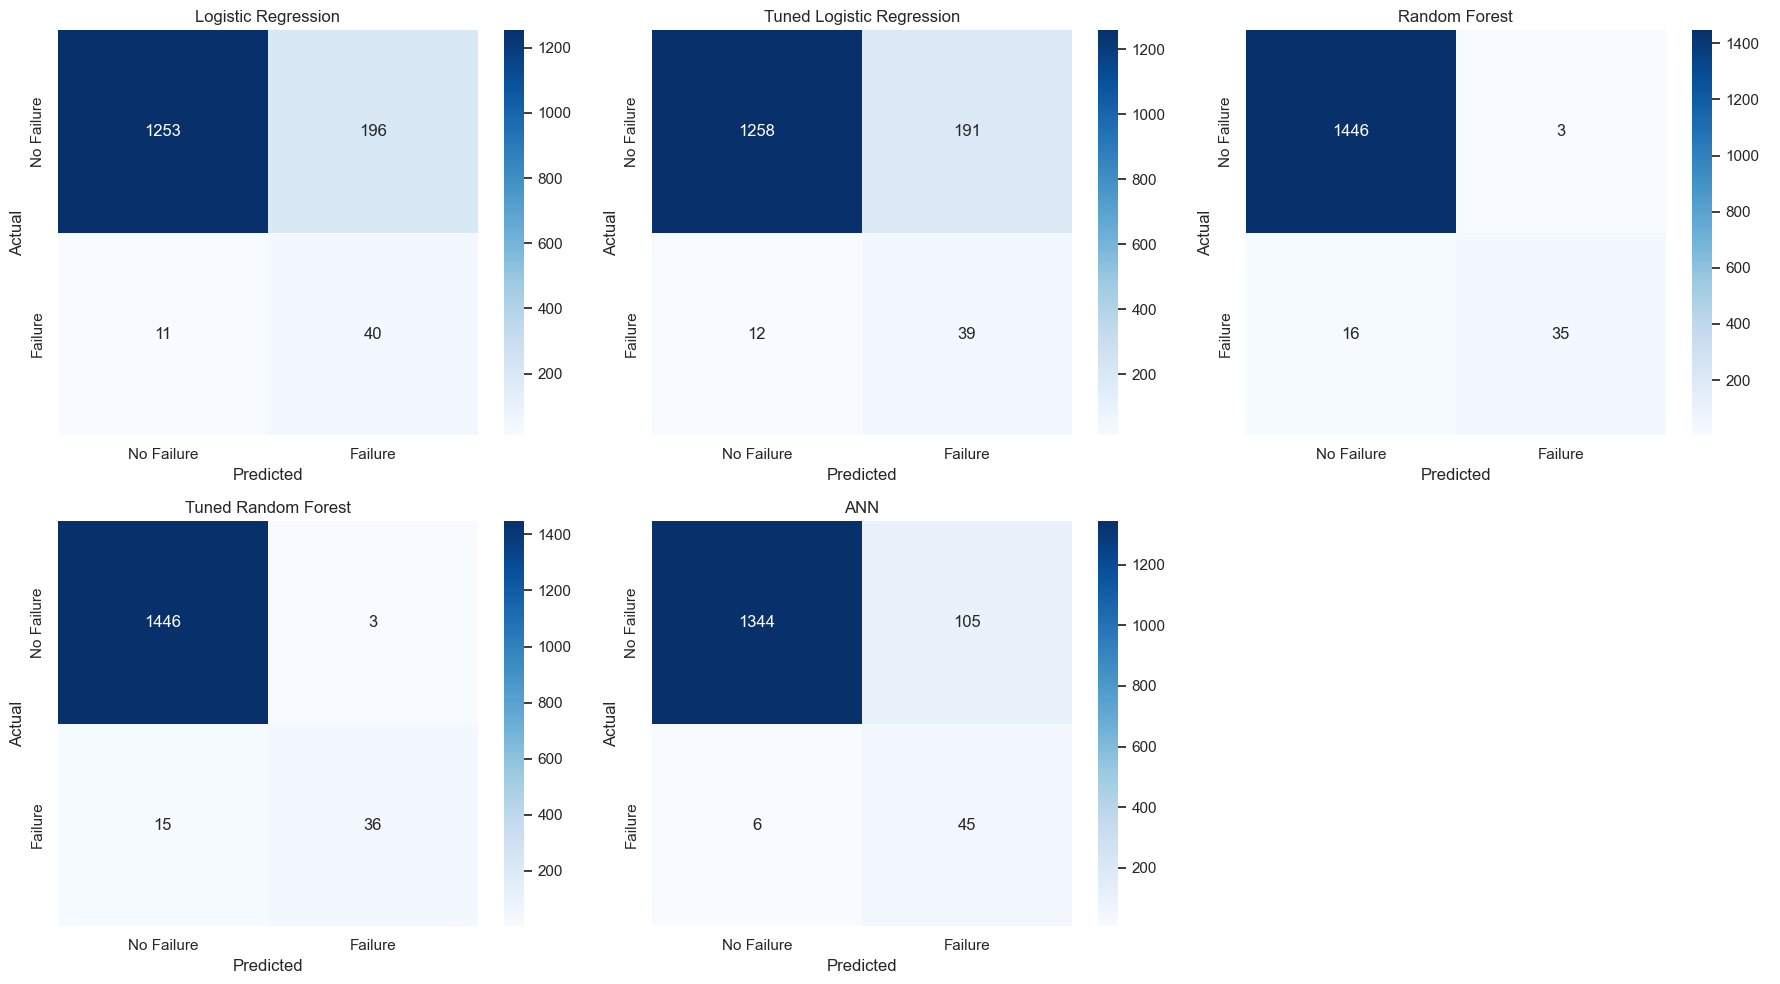

In [69]:
n_models = len(validation_probabilities)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.array(axes).flatten()

for ax, (model_name, probabilities) in zip(axes, validation_probabilities.items()):

    predictions = (probabilities >= 0.5).astype(int)

    cm = confusion_matrix(y_val_actual, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

# Hide unused subplot panels
for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### False positive and false negative analysis

In [70]:
error_results = []

for model_name, probabilities in validation_probabilities.items():

    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_actual, predictions, labels=[0, 1]
    ).ravel()

    error_results.append({
        "Model": model_name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

error_analysis = pd.DataFrame(error_results)

error_analysis

,Model,True Negatives,False Positives,False Negatives,True Positives
0,Logistic Regression,1253,196,11,40
1,Tuned Logistic Regression,1258,191,12,39
2,Random Forest,1446,3,16,35
3,Tuned Random Forest,1446,3,15,36
4,ANN,1344,105,6,45


- False positive: The model raises a maintenance alert for a machine that does not fail. This may cause an unnecessary inspection.
- False negative: The model misses a machine that actually fails. This may result in unexpected downtime or equipment damage.
For predictive maintenance, false negatives can be especially costly. However, too many false positives can also waste maintenance resources.

### Overfitting check – training vs validation performance

A model that scores much higher on the training data than on the validation
data has memorised the training set. We compare PR-AUC, ROC-AUC and recall
(at the 0.5 threshold) on both sets.

In [71]:
train_probabilities = {
    name: predict(X_train) for name, predict in model_predictors.items()
}

y_train_actual = np.array(y_train)

overfit_rows = []

for name in model_predictors:

    train_p = train_probabilities[name]
    val_p = validation_probabilities[name]

    overfit_rows.append({
        "Model": name,
        "Train PR-AUC": average_precision_score(y_train_actual, train_p),
        "Validation PR-AUC": average_precision_score(y_val_actual, val_p),
        "PR-AUC Gap": average_precision_score(y_train_actual, train_p)
                      - average_precision_score(y_val_actual, val_p),
        "Train ROC-AUC": roc_auc_score(y_train_actual, train_p),
        "Validation ROC-AUC": roc_auc_score(y_val_actual, val_p),
        "Train Recall@0.5": recall_score(y_train_actual, (train_p >= 0.5).astype(int)),
        "Validation Recall@0.5": recall_score(y_val_actual, (val_p >= 0.5).astype(int))
    })

overfit_df = pd.DataFrame(overfit_rows).round(4)

display(overfit_df)

,Model,Train PR-AUC,Validation PR-AUC,PR-AUC Gap,Train ROC-AUC,Validation ROC-AUC,Train Recall@0.5,Validation Recall@0.5
0,Logistic Regression,0.4741,0.3561,0.1180,0.9339,0.9048,0.8650,0.7843
1,Tuned Logistic Regression,0.5053,0.3927,0.1126,0.9273,0.9008,0.8439,0.7647
2,Random Forest,1.0000,0.8744,0.1256,1.0000,0.9804,1.0000,0.6863
3,Tuned Random Forest,0.9999,0.8634,0.1365,1.0000,0.9880,0.9916,0.7059
4,ANN,0.8084,0.7279,0.0805,0.9830,0.9761,0.9367,0.8824


### Are the models overfitting?

Overfitting means the model **memorises** the training data instead of learning
general patterns.

- **Random Forest:** yes, it memorises. Its training PR-AUC is a perfect 1.00,
  but 0.86–0.87 on validation. Even so, it is **still the best model** on new
  data.
- **ANN:** the smallest gap (0.81 on training → 0.73 on validation). Dropout and
  early stopping helped.
- **Logistic Regression:** the opposite problem, **underfitting**. It scores low
  even on training data (about 0.47–0.51), because the patterns are not straight
  lines.

### Effect of class imbalance – class-weighted vs unweighted training

To measure how the 96.6% / 3.4% imbalance affects the models, we retrain
Logistic Regression, Random Forest and the ANN **without** class weights, using
the same data, features, settings and seed, and compare them with the
class-weighted versions on the validation set.

,Model,Training,Precision@0.5,Recall@0.5,F1@0.5,ROC-AUC,PR-AUC
0,Logistic Regression,Unweighted,0.5500,0.2157,0.3099,0.9004,0.3911
1,Logistic Regression,Class-weighted,0.1695,0.7843,0.2787,0.9048,0.3561
2,Random Forest,Unweighted,0.9348,0.8431,0.8866,0.9819,0.9084
3,Random Forest,Class-weighted,0.9211,0.6863,0.7865,0.9804,0.8744
4,ANN,Unweighted,0.8108,0.5882,0.6818,0.9769,0.7669
5,ANN,Class-weighted,0.3000,0.8824,0.4478,0.9761,0.7279


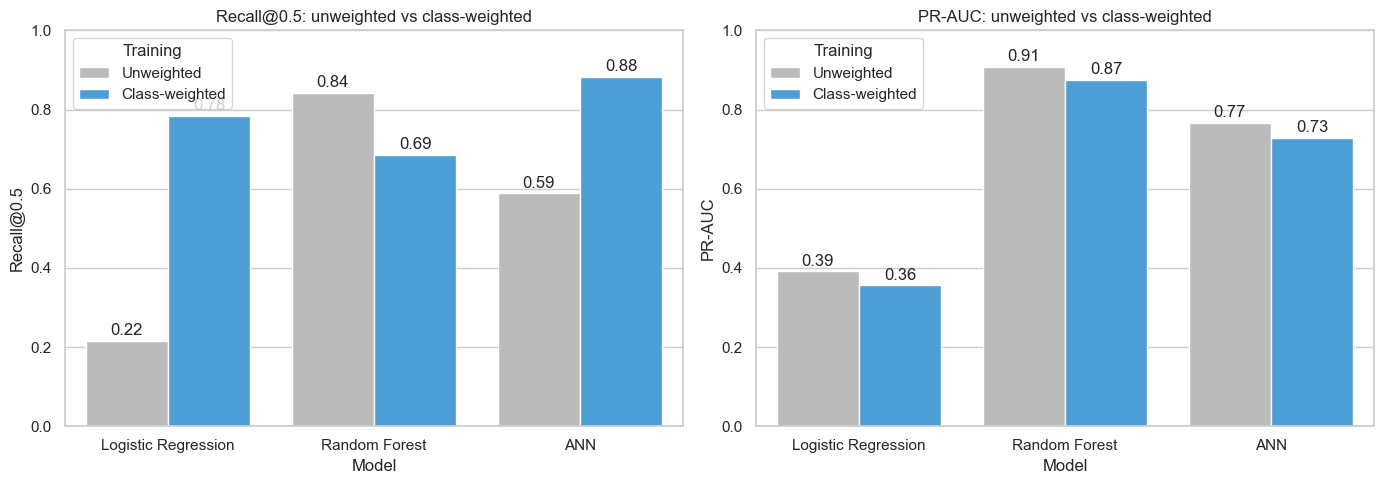

In [72]:
imbalance_rows = []

unweighted_sklearn_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
}

unweighted_probabilities = {}

for name, model in unweighted_sklearn_models.items():
    model.fit(X_train_processed, y_train)
    unweighted_probabilities[name] = model.predict_proba(X_val_processed)[:, 1]

# Unweighted ANN (same architecture, optimizer, callbacks and seed as the main ANN)
tf.keras.utils.set_random_seed(RANDOM_STATE)

ann_unweighted = Sequential([
    Input(shape=(X_train_ann.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.30),
    Dense(32, activation="relu"),
    Dropout(0.20),
    Dense(1, activation="sigmoid")
])

ann_unweighted.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy")

ann_unweighted.fit(
    X_train_ann, y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=50, batch_size=32,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=0.00001)
    ],
    verbose=0
)

unweighted_probabilities["ANN"] = ann_unweighted.predict(X_val_ann, verbose=0).flatten()

for name in ["Logistic Regression", "Random Forest", "ANN"]:
    for setting, probs in [
        ("Unweighted", unweighted_probabilities[name]),
        ("Class-weighted", validation_probabilities[name])
    ]:
        preds = (probs >= 0.5).astype(int)
        imbalance_rows.append({
            "Model": name,
            "Training": setting,
            "Precision@0.5": precision_score(y_val_actual, preds, zero_division=0),
            "Recall@0.5": recall_score(y_val_actual, preds, zero_division=0),
            "F1@0.5": f1_score(y_val_actual, preds, zero_division=0),
            "ROC-AUC": roc_auc_score(y_val_actual, probs),
            "PR-AUC": average_precision_score(y_val_actual, probs)
        })

imbalance_df = pd.DataFrame(imbalance_rows).round(4)
display(imbalance_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ["Recall@0.5", "PR-AUC"]):
    sns.barplot(data=imbalance_df, x="Model", y=metric, hue="Training", ax=ax,
                palette=["#BBBBBB", "#36A2EB"])
    ax.set_ylim(0, 1)
    ax.set_title(f"{metric}: unweighted vs class-weighted")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()

### How did class imbalance affect the models?

We trained each model twice, **with** and **without** class weights.

**What class weights did:**
- They made the models predict "failure" **more often**.
- Recall went up, so more failures were caught. For example, Logistic
  Regression went from 22% to 78%.
- Precision went down, so there were more false alarms. For example, Logistic
  Regression went from 55% to 17%.

**What class weights did not do:**
- They did **not** make the models better at ranking risky vs safe machines.
  PR-AUC stayed the same or dropped a little:
  - Logistic Regression: 0.39 → 0.36
  - Random Forest: 0.91 → 0.87
  - ANN: 0.77 → 0.73


### Plot ROC curves

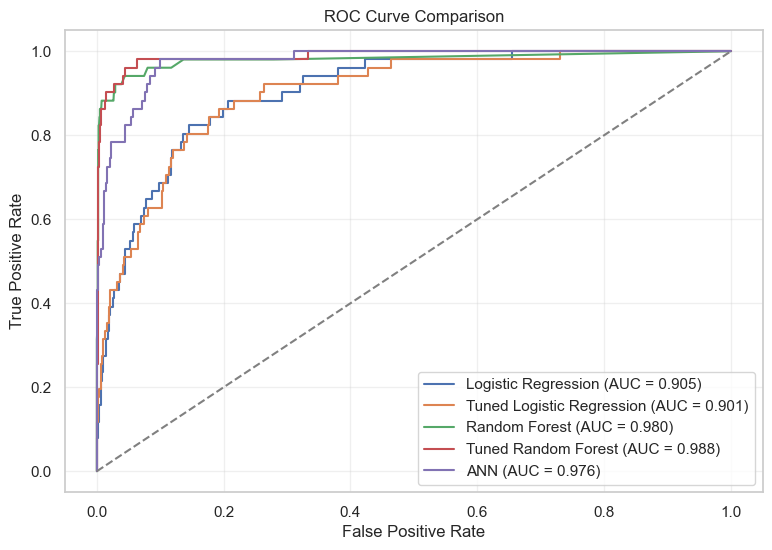

In [73]:
plt.figure(figsize=(9, 6))

for model_name, probabilities in validation_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_val_actual, probabilities
    )

    auc_value = roc_auc_score(y_val_actual, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### What the ROC curves show

- **Random Forests** (0.98–0.99) and the **ANN** (0.98) separate failures from
  non-failures very well.
- **Logistic Regression** is weaker (about 0.90).

**Note:** with so few failures, ROC-AUC looks high for almost every model. That
is why we use **PR-AUC** as our main metric: it shows the differences much more
clearly.

### Plot Precision-Recall curves

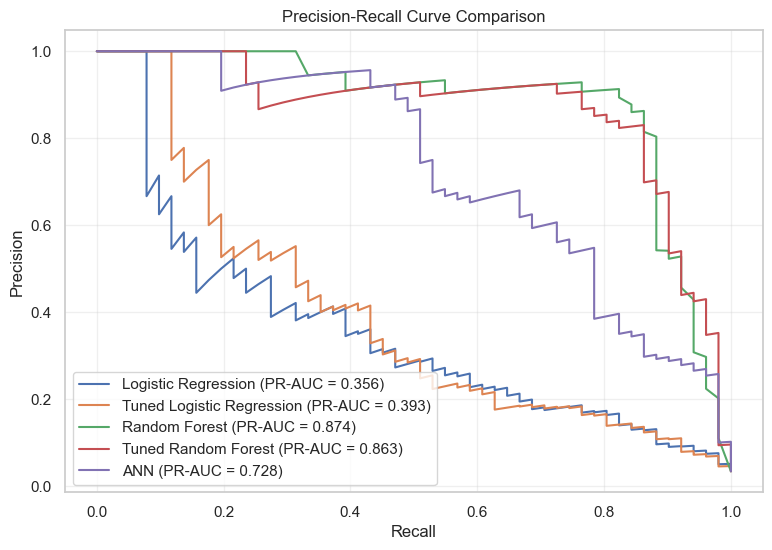

In [74]:
plt.figure(figsize=(9, 6))

for model_name, probabilities in validation_probabilities.items():

    precision_values, recall_values, thresholds = precision_recall_curve(
        y_val_actual, probabilities
    )

    pr_auc = average_precision_score(
        y_val_actual, probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{model_name} (PR-AUC = {pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### What the Precision–Recall curves show

The differences are much clearer here than on the ROC curves:

| Model | PR-AUC |
|---|---|
| Random Forest | 0.87 |
| Tuned Random Forest | 0.86 |
| ANN | 0.73 |
| Logistic Regression | 0.36–0.39 |

The Random Forest keeps **high precision** (few false alarms) until it has
caught about 70% of failures. The ANN catches many failures, but gives false
alarms sooner.

### Compare different decision thresholds

In [75]:
threshold_results = []

# Fine steps at the low end (0.01-0.04) so that the cost-optimal threshold is
# not stuck at the edge of the tested range
threshold_values = np.round(
    np.concatenate([np.arange(0.01, 0.05, 0.01), np.arange(0.05, 1.00, 0.05)]),
    2
)

for model_name, probabilities in validation_probabilities.items():

    for threshold in threshold_values:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_actual, predictions, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(float(threshold), 2),
            "Precision": precision_score(
                y_val_actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_actual, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_val_actual, predictions, zero_division=0
            ),
            "False Positives": fp,
            "False Negatives": fn
        })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df.head(10)

,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives
0,Logistic Regression,0.01,0.039021,1.000000,0.075110,1256,0
1,Logistic Regression,0.02,0.043257,1.000000,0.082927,1128,0
2,Logistic Regression,0.03,0.046875,1.000000,0.089552,1037,0
3,Logistic Regression,0.04,0.050049,1.000000,0.095327,968,0
4,Logistic Regression,0.05,0.051230,0.980392,0.097371,926,1
5,Logistic Regression,0.10,0.063452,0.980392,0.119190,738,1
6,Logistic Regression,0.15,0.076563,0.960784,0.141823,591,2
7,Logistic Regression,0.20,0.087751,0.941176,0.160535,499,3
8,Logistic Regression,0.25,0.097046,0.901961,0.175238,428,5
9,Logistic Regression,0.30,0.107399,0.882353,0.191489,374,6


### Visualize threshold vs precision and recall

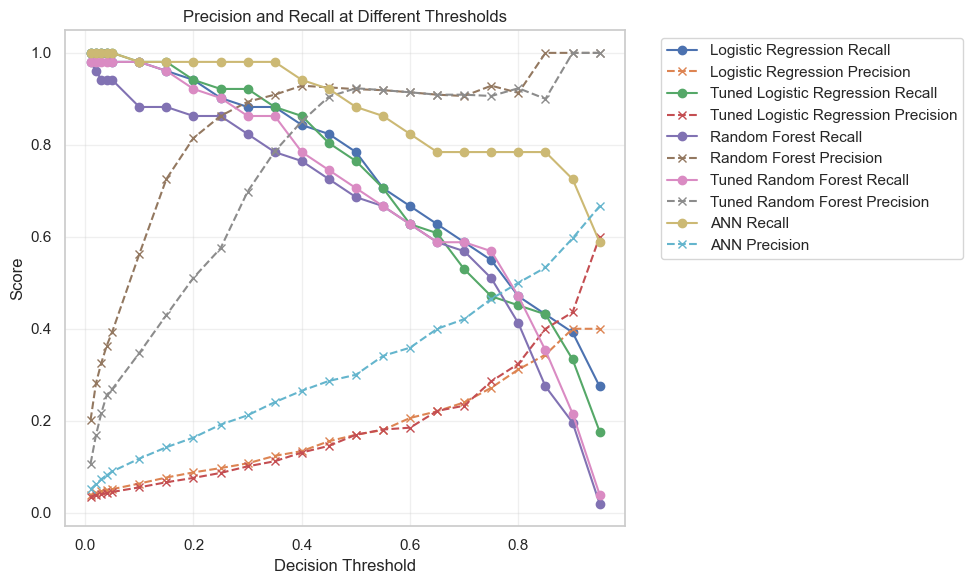

In [76]:
plt.figure(figsize=(10, 6))

for model_name in validation_probabilities.keys():

    model_data = threshold_results_df[
        threshold_results_df["Model"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["Recall"],
        marker="o",
        label=f"{model_name} Recall"
    )

    plt.plot(
        model_data["Threshold"],
        model_data["Precision"],
        marker="x",
        linestyle="--",
        label=f"{model_name} Precision"
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### What changing the threshold does

- **Lower threshold** → the model raises alerts more easily → **catches more
  failures** but gives **more false alarms**.
- **Higher threshold** → fewer alerts → fewer false alarms but **more missed
  failures**.

The default threshold of 0.5 is **too strict for Random Forest**: it misses
15–16 of the 51 failures. Random Forest works best with low thresholds
(0.05–0.25). So we choose the threshold using **costs**, not just 0.5.

### Hypothetical maintenance cost analysis

**Assumption (not measured):** the costs below are hypothetical figures chosen
for illustration. They are not from the dataset.

- Unnecessary inspection (false positive): ₹2,000
- Missed failure (false negative): ₹50,000, covering downtime, repair and late delivery

The ratio of 25:1 matters more than the absolute values, so we test other
ratios in the sensitivity analysis below.

In [77]:
# Hypothetical costs - change these if required
cost_per_false_positive = 2000
cost_per_false_negative = 50000

threshold_results_df["Estimated Cost"] = (
    threshold_results_df["False Positives"] * cost_per_false_positive
    +
    threshold_results_df["False Negatives"] * cost_per_false_negative
)

threshold_results_df.head(10)

,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,Estimated Cost
0,Logistic Regression,0.01,0.039021,1.000000,0.075110,1256,0,2512000
1,Logistic Regression,0.02,0.043257,1.000000,0.082927,1128,0,2256000
2,Logistic Regression,0.03,0.046875,1.000000,0.089552,1037,0,2074000
3,Logistic Regression,0.04,0.050049,1.000000,0.095327,968,0,1936000
4,Logistic Regression,0.05,0.051230,0.980392,0.097371,926,1,1902000
5,Logistic Regression,0.10,0.063452,0.980392,0.119190,738,1,1526000
6,Logistic Regression,0.15,0.076563,0.960784,0.141823,591,2,1282000
7,Logistic Regression,0.20,0.087751,0.941176,0.160535,499,3,1148000
8,Logistic Regression,0.25,0.097046,0.901961,0.175238,428,5,1106000
9,Logistic Regression,0.30,0.107399,0.882353,0.191489,374,6,1048000


### Find the lowest-cost model and threshold on validation data

In [78]:
# Find the lowest-cost threshold for each model
# (stable sort so that ties are always resolved the same way)
best_threshold_per_model = (
    threshold_results_df
    .sort_values(["Estimated Cost", "Threshold"], ascending=[True, False], kind="mergesort")
    .groupby("Model")
    .head(1)
    .sort_values("Estimated Cost", kind="mergesort")
    .reset_index(drop=True)
)

best_threshold_per_model

,Model,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives,Estimated Cost
0,Tuned Random Forest,0.15,0.429825,0.960784,0.593939,65,2,230000
1,Random Forest,0.05,0.393443,0.941176,0.554913,74,3,298000
2,ANN,0.35,0.240385,0.980392,0.386100,158,1,366000
3,Logistic Regression,0.45,0.155556,0.823529,0.261682,228,9,906000
4,Tuned Logistic Regression,0.40,0.130952,0.862745,0.227390,292,7,934000


In [79]:
selected_result = best_threshold_per_model.iloc[0]

selected_model_name = selected_result["Model"]
best_threshold = selected_result["Threshold"]

print("Selected Model:", selected_model_name)
print("Selected Threshold:", best_threshold)
print("Validation False Positives:", selected_result["False Positives"])
print("Validation False Negatives:", selected_result["False Negatives"])
print("Estimated Validation Cost: ₹", selected_result["Estimated Cost"])

Selected Model: Tuned Random Forest
Selected Threshold: 0.15
Validation False Positives: 65
Validation False Negatives: 2
Estimated Validation Cost: ₹ 230000


### Cost sensitivity analysis

The 25:1 cost ratio is an assumption. We check whether the recommended model and
threshold change when a missed failure is 10×, 25× or 50× as expensive as an
unnecessary inspection. The inspection cost stays at ₹2,000.

In [80]:
cost_scenarios = {
    "10:1 (missed failure = ₹20,000)": 20000,
    "25:1 (missed failure = ₹50,000, base case)": 50000,
    "50:1 (missed failure = ₹1,00,000)": 100000
}

sensitivity_rows = []
per_model_rows = []

for scenario, fn_cost in cost_scenarios.items():

    temp = threshold_results_df.copy()
    temp["Scenario Cost"] = (
        temp["False Positives"] * cost_per_false_positive
        + temp["False Negatives"] * fn_cost
    )

    temp = temp.sort_values(["Scenario Cost", "Threshold"], ascending=[True, False], kind="mergesort")

    best = temp.iloc[0]
    sensitivity_rows.append({
        "Scenario": scenario,
        "Best Model": best["Model"],
        "Best Threshold": best["Threshold"],
        "Recall": round(best["Recall"], 4),
        "Precision": round(best["Precision"], 4),
        "False Positives": best["False Positives"],
        "False Negatives": best["False Negatives"],
        "Validation Cost (₹)": best["Scenario Cost"]
    })

    for model_name, group in temp.groupby("Model", sort=False):
        row = group.iloc[0]
        per_model_rows.append({
            "Scenario": scenario,
            "Model": model_name,
            "Threshold": row["Threshold"],
            "Cost (₹)": row["Scenario Cost"]
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)

per_model_sensitivity = pd.DataFrame(per_model_rows).pivot(
    index="Model", columns="Scenario", values="Threshold"
)
print("Cost-optimal threshold for each model under each cost scenario:")
display(per_model_sensitivity)

,Scenario,Best Model,Best Threshold,Recall,Precision,False Positives,False Negatives,Validation Cost (₹)
0,"10:1 (missed failure = ₹20,000)",Random Forest,0.25,0.8627,0.8627,7,7,154000
1,"25:1 (missed failure = ₹50,000, base case)",Tuned Random Forest,0.15,0.9608,0.4298,65,2,230000
2,"50:1 (missed failure = ₹1,00,000)",Tuned Random Forest,0.10,0.9804,0.3472,94,1,288000


Cost-optimal threshold for each model under each cost scenario:


Scenario,"10:1 (missed failure = ₹20,000)","25:1 (missed failure = ₹50,000, base case)","50:1 (missed failure = ₹1,00,000)"
Model,,,
ANN,0.85,0.35,0.35
Logistic Regression,0.60,0.45,0.35
Random Forest,0.25,0.05,0.05
Tuned Logistic Regression,0.65,0.40,0.30
Tuned Random Forest,0.35,0.15,0.10


### Does the recommendation change if costs change?

We tried three cost ratios (how much worse a missed failure is than a false alarm):

| Cost ratio | Best model | Best threshold | False alarms | Missed failures |
|---|---|---|---|---|
| 10 : 1 | Random Forest | 0.25 | 7 | 7 |
| 25 : 1 (our main case) | Tuned Random Forest | 0.15 | 65 | 2 |
| 50 : 1 | Tuned Random Forest | 0.10 | 94 | 1 |

**Random Forest is always the best choice**. Only the
threshold changes: the more expensive a missed failure is, the lower the
threshold should be. The company must confirm its real costs before setting the
final threshold.

### Final evaluation on the test dataset

In [81]:
# Get test probabilities from the selected model (same wrapper functions as validation)
test_probabilities = model_predictors[selected_model_name](X_test)

# Apply the selected validation threshold
y_test_actual = np.array(y_test)

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)


print("Selected Model:", selected_model_name)
print("Selected Threshold:", best_threshold)

Selected Model: Tuned Random Forest
Selected Threshold: 0.15


### Calculate final test metrics

In [82]:
test_accuracy = accuracy_score(y_test_actual, test_predictions)

test_precision = precision_score(
    y_test_actual, test_predictions, zero_division=0
)

test_recall = recall_score(
    y_test_actual, test_predictions, zero_division=0
)

test_f1 = f1_score(
    y_test_actual, test_predictions, zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test_actual, test_probabilities
)

test_pr_auc = average_precision_score(
    y_test_actual, test_probabilities
)

final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Test Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc,
        test_pr_auc
    ]
})

final_test_results["Test Score"] = final_test_results["Test Score"].round(4)

final_test_results

,Metric,Test Score
0,Accuracy,0.9480
1,Precision,0.3884
2,Recall,0.9216
3,F1 Score,0.5465
4,ROC-AUC,0.9783
5,PR-AUC,0.8916


### Final test confusion matrix

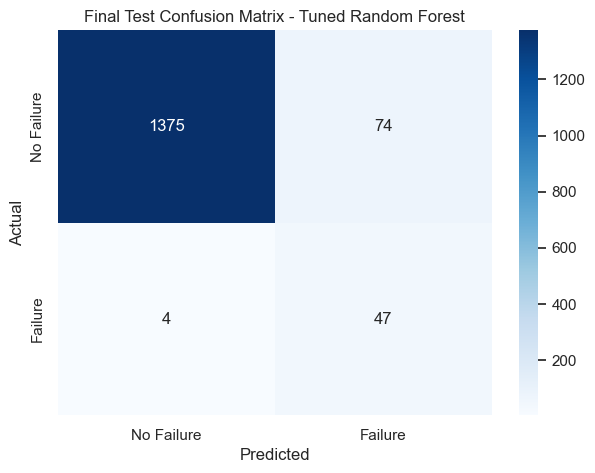

True Negatives: 1375
False Positives: 74
False Negatives: 4
True Positives: 47


In [83]:
cm = confusion_matrix(
    y_test_actual,
    test_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title(f"Final Test Confusion Matrix - {selected_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

### Final false positive and false negative cost

In [84]:
final_false_positive_cost = fp * cost_per_false_positive
final_false_negative_cost = fn * cost_per_false_negative

final_total_cost = (
    final_false_positive_cost + final_false_negative_cost
)

print("Cost of Unnecessary Inspections: ₹", final_false_positive_cost)
print("Cost of Missed Failures: ₹", final_false_negative_cost)
print("Total Estimated Test Cost: ₹", final_total_cost)

Cost of Unnecessary Inspections: ₹ 148000
Cost of Missed Failures: ₹ 200000
Total Estimated Test Cost: ₹ 348000


### Classification report

In [85]:
print(
    classification_report(
        y_test_actual,
        test_predictions,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       1.00      0.95      0.97      1449
     Failure       0.39      0.92      0.55        51

    accuracy                           0.95      1500
   macro avg       0.69      0.94      0.76      1500
weighted avg       0.98      0.95      0.96      1500



### All models on the test set (reported after selection)

**Important:** the model and threshold were already fixed using validation data.
The table below is reported for transparency only and was **not** used to choose
the model. Each model is shown at the default threshold of 0.5 and at its own
validation-selected cost-optimal threshold.

In [86]:
best_threshold_lookup = dict(
    zip(best_threshold_per_model["Model"], best_threshold_per_model["Threshold"])
)

test_probabilities_all = {
    name: predict(X_test) for name, predict in model_predictors.items()
}

test_rows = []

for name, probs in test_probabilities_all.items():
    for threshold_type, threshold in [
        ("Default", 0.5),
        ("Validation cost-optimal", best_threshold_lookup[name])
    ]:
        preds = (probs >= threshold).astype(int)
        tn, fp_, fn_, tp = confusion_matrix(y_test_actual, preds, labels=[0, 1]).ravel()
        test_rows.append({
            "Model": name,
            "Threshold Type": threshold_type,
            "Threshold": threshold,
            "Precision": precision_score(y_test_actual, preds, zero_division=0),
            "Recall": recall_score(y_test_actual, preds, zero_division=0),
            "F1 Score": f1_score(y_test_actual, preds, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test_actual, probs),
            "PR-AUC": average_precision_score(y_test_actual, probs),
            "False Positives": fp_,
            "False Negatives": fn_,
            "Estimated Cost (₹)": fp_ * cost_per_false_positive + fn_ * cost_per_false_negative
        })

test_comparison_df = pd.DataFrame(test_rows).round(4)
display(test_comparison_df)

,Model,Threshold Type,Threshold,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,False Positives,False Negatives,Estimated Cost (₹)
0,Logistic Regression,Default,0.50,0.1796,0.8627,0.2973,0.9372,0.4432,201,7,752000
1,Logistic Regression,Validation cost-optimal,0.45,0.1568,0.8824,0.2663,0.9372,0.4432,242,6,784000
2,Tuned Logistic Regression,Default,0.50,0.1685,0.9020,0.2840,0.9275,0.4540,227,5,704000
3,Tuned Logistic Regression,Validation cost-optimal,0.40,0.1247,0.9020,0.2190,0.9275,0.4540,323,5,896000
4,Random Forest,Default,0.50,1.0000,0.7647,0.8667,0.9857,0.9032,0,12,600000
5,Random Forest,Validation cost-optimal,0.05,0.3750,0.8824,0.5263,0.9857,0.9032,75,6,450000
6,Tuned Random Forest,Default,0.50,0.9535,0.8039,0.8723,0.9783,0.8916,2,10,504000
7,Tuned Random Forest,Validation cost-optimal,0.15,0.3884,0.9216,0.5465,0.9783,0.8916,74,4,348000
8,ANN,Default,0.50,0.2876,0.8627,0.4314,0.9760,0.7061,109,7,568000
9,ANN,Validation cost-optimal,0.35,0.2172,0.9412,0.3529,0.9760,0.7061,173,3,496000


### Generalisation check – train vs validation vs test PR-AUC

In [87]:
generalisation_df = pd.DataFrame({
    "Model": list(model_predictors.keys()),
    "Train PR-AUC": [average_precision_score(y_train_actual, train_probabilities[n]) for n in model_predictors],
    "Validation PR-AUC": [average_precision_score(y_val_actual, validation_probabilities[n]) for n in model_predictors],
    "Test PR-AUC": [average_precision_score(y_test_actual, test_probabilities_all[n]) for n in model_predictors]
}).round(4)

display(generalisation_df)

,Model,Train PR-AUC,Validation PR-AUC,Test PR-AUC
0,Logistic Regression,0.4741,0.3561,0.4432
1,Tuned Logistic Regression,0.5053,0.3927,0.4540
2,Random Forest,1.0000,0.8744,0.9032
3,Tuned Random Forest,0.9999,0.8634,0.8916
4,ANN,0.8084,0.7279,0.7061


### Final results on the test set (data the model has never seen)

**Selected model:** Tuned Random Forest, threshold 0.15.

| Result | Value |
|---|---|
| Failures caught | **47 of 51 (recall 92.2%)** |
| Failures missed | 4 |
| False alarms | 74 out of 1,449 healthy records |
| Precision | 38.8% |
| PR-AUC | 0.892 |
| Hypothetical cost | **₹3,48,000** (the lowest of all models) |

**What this tells us:**
- Test results are **close to the validation results**, so the model works on
  new data and was not just lucky.
- The normal Random Forest and the tuned Random Forest perform **almost the
  same**.
- The ANN (cost ₹4,96,000) and Logistic Regression (₹7–9 lakh) are clearly worse.

These test results were calculated **after** choosing the model, so the test set
was not used to make the choice.

## Phase 3 – Conclusion

- **Best model: Random Forest.** It is best at telling failures from
  non-failures (PR-AUC 0.86–0.87), ahead of the ANN (0.73) and Logistic
  Regression (0.36–0.39).
- **Accuracy is misleading.** Random Forest has 98.8% accuracy at threshold 0.5,
  but still misses about 30% of failures.
- **Best threshold: 0.15.** With our assumed costs (₹2,000 per false alarm,
  ₹50,000 per missed failure), this gives the lowest cost.
- **Test result:** catches 92% of failures, with 74 false alarms and a cost of
  ₹3,48,000.
- **Stable choice:** Random Forest stays the best even when the costs change.
- **Weakness:** Random Forest memorises the training data, but it still works
  best on new data.

**Recommendation:** use the **Random Forest with threshold 0.15**, and adjust
the threshold once the real costs are known.

## Phase 4 – Research and Controlled Experiment

### Our hypotheses (written before running the experiment)

**Main question: is the ANN better than traditional ML?**
- H₀ (null): The ANN is **not** better than the tuned Random Forest (PR-AUC).
- H₁ (alternative): The ANN **is** better than the tuned Random Forest.

**Experiment: does the learning rate matter?**
- H₀: Changing the learning rate (0.0001, 0.001, 0.01) makes **no difference**.
- H₁: The learning rate **does** change performance. We expect 0.0001 to be too
  slow to learn well within 50 epochs.

**How we keep it fair (controlled experiment):**
- We change **only one thing**: the learning rate.
- Everything else stays the same: layers, dropout, optimizer (Adam), batch size
  (32), max epochs (50), callbacks, class weights, data and threshold (0.5).
- Each setting is run **5 times** with different random seeds (42, 52, 62, 72, 82).
- The Random Forest is also run 5 times with the same seeds, for a fair comparison.

**How we decide:** a difference counts as **real** only if the t-test gives
p < 0.05 **and** the 95% confidence interval does not include 0. Otherwise it is
just a small difference that could be due to chance.

### Create an ANN model function

In [88]:
def create_ann_model(learning_rate):

    model = Sequential([
        Input(shape=(X_train_processed.shape[1],)),

        Dense(64, activation="relu"),
        Dropout(0.30),

        Dense(32, activation="relu"),
        Dropout(0.20),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
    )

    return model

Explanation: The function creates the same ANN structure every time. The learning_rate parameter controls only the learning rate of the Adam optimizer.

### Define experiment settings

In [89]:
learning_rates = [0.001, 0.0001, 0.01]

experiment_names = {
    0.001: "Baseline",
    0.0001: "Low Learning Rate",
    0.01: "High Learning Rate"
}

random_seeds = [42, 52, 62, 72, 82]

experiment_results = []
experiment_histories = {}

print("Experiment settings prepared successfully.")

Experiment settings prepared successfully.


### Run the controlled experiments

In [90]:
for learning_rate in learning_rates:

    for seed in random_seeds:

        print("\n------------------------------")
        print("Experiment:", experiment_names[learning_rate])
        print("Learning Rate:", learning_rate)
        print("Random Seed:", seed)
        print("------------------------------")

        # Set random seed
        tf.keras.utils.set_random_seed(seed)

        # Create ANN
        model = create_ann_model(learning_rate)

        # Early stopping
        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True
        )

        # Reduce learning rate when validation loss stops improving
        reduce_lr = ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=0.00001
        )

        # Train ANN
        history = model.fit(
            X_train_processed,
            y_train,
            validation_data=(X_val_processed, y_val),
            epochs=50,
            batch_size=32,
            class_weight=class_weights,
            callbacks=[early_stop, reduce_lr],
            verbose=0
        )

        # Predict validation probabilities
        probabilities = model.predict(
            X_val_processed,
            verbose=0
        ).flatten()

        # Apply the same threshold for every experiment
        predictions = (probabilities >= 0.5).astype(int)

        # Calculate metrics
        result = {
            "Experiment": experiment_names[learning_rate],
            "Learning Rate": learning_rate,
            "Seed": seed,
            "Epochs": len(history.history["loss"]),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_val, probabilities
            ),
            "PR-AUC": average_precision_score(
                y_val, probabilities
            )
        }

        experiment_results.append(result)

        experiment_histories[(learning_rate, seed)] = history.history

        print("Validation PR-AUC:", round(result["PR-AUC"], 4))
        print("Validation Recall:", round(result["Recall"], 4))

print("\nAll experiments completed.")


------------------------------
Experiment: Baseline
Learning Rate: 0.001
Random Seed: 42
------------------------------


Validation PR-AUC: 0.7279
Validation Recall: 0.8824

------------------------------
Experiment: Baseline
Learning Rate: 0.001
Random Seed: 52
------------------------------


Validation PR-AUC: 0.7084
Validation Recall: 0.8824

------------------------------
Experiment: Baseline
Learning Rate: 0.001
Random Seed: 62
------------------------------


Validation PR-AUC: 0.714
Validation Recall: 0.8824

------------------------------
Experiment: Baseline
Learning Rate: 0.001
Random Seed: 72
------------------------------


Validation PR-AUC: 0.6781
Validation Recall: 0.8627

------------------------------
Experiment: Baseline
Learning Rate: 0.001
Random Seed: 82
------------------------------


Validation PR-AUC: 0.6882
Validation Recall: 0.8627

------------------------------
Experiment: Low Learning Rate
Learning Rate: 0.0001
Random Seed: 42
------------------------------


... (6 outputs left out)

Validation PR-AUC: 0.7375
Validation Recall: 0.9412

------------------------------
Experiment: High Learning Rate
Learning Rate: 0.01
Random Seed: 62
------------------------------


Validation PR-AUC: 0.7131
Validation Recall: 0.9216

------------------------------
Experiment: High Learning Rate
Learning Rate: 0.01
Random Seed: 72
------------------------------


Validation PR-AUC: 0.7145
Validation Recall: 0.8627

------------------------------
Experiment: High Learning Rate
Learning Rate: 0.01
Random Seed: 82
------------------------------


Validation PR-AUC: 0.7164
Validation Recall: 0.8431

All experiments completed.


For each learning rate:
1. We create a new ANN.
2. We train it using the same training data.
3. We use the same validation data.
4. We calculate validation metrics.
5. We repeat the experiment with five different random seeds.

We use threshold 0.5 for this controlled comparison, so that only the learning
rate and the random initialisation vary. PR-AUC, the main metric, does not depend
on the threshold.

### Compare experiment results

In [91]:
experiment_df = pd.DataFrame(experiment_results)

experiment_df.round(4)

,Experiment,Learning Rate,Seed,Epochs,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Baseline,0.0010,42,49,0.3000,0.8824,0.4478,0.9761,0.7279
1,Baseline,0.0010,52,45,0.2961,0.8824,0.4433,0.9742,0.7084
2,Baseline,0.0010,62,34,0.2980,0.8824,0.4455,0.9748,0.7140
3,Baseline,0.0010,72,40,0.2953,0.8627,0.4400,0.9688,0.6781
4,Baseline,0.0010,82,31,0.2953,0.8627,0.4400,0.9707,0.6882
5,Low Learning Rate,0.0001,42,50,0.1737,0.8039,0.2857,0.9351,0.5021
6,Low Learning Rate,0.0001,52,50,0.1438,0.8235,0.2449,0.9090,0.4299
7,Low Learning Rate,0.0001,62,50,0.1907,0.8039,0.3083,0.9429,0.5428
8,Low Learning Rate,0.0001,72,50,0.1886,0.8431,0.3082,0.9372,0.4728
9,Low Learning Rate,0.0001,82,50,0.2049,0.8235,0.3281,0.9355,0.4965


### Calculate mean and standard deviation

In [92]:
experiment_summary = (
    experiment_df
    .groupby(["Experiment", "Learning Rate"])
    .agg({
        "Precision": ["mean", "std"],
        "Recall": ["mean", "std"],
        "F1 Score": ["mean", "std"],
        "ROC-AUC": ["mean", "std"],
        "PR-AUC": ["mean", "std"],
        "Epochs": ["mean", "std"]
    })
)

experiment_summary.round(4)

Precision          Recall         F1 Score  \
                                      mean     std    mean     std     mean   
Experiment         Learning Rate                                              
Baseline           0.0010           0.2969  0.0020  0.8745  0.0107   0.4433   
High Learning Rate 0.0100           0.3447  0.0310  0.8902  0.0407   0.4958   
Low Learning Rate  0.0001           0.1803  0.0232  0.8196  0.0164   0.2951   

                                         ROC-AUC          PR-AUC          \
                                     std    mean     std    mean     std   
Experiment         Learning Rate                                           
Baseline           0.0010         0.0034  0.9729  0.0030  0.7033  0.0201   
High Learning Rate 0.0100         0.0291  0.9756  0.0046  0.7255  0.0151   
Low Learning Rate  0.0001         0.0318  0.9319  0.0132  0.4888  0.0415   

                                 Epochs          
                                   mean     std  
Experiment         Learning Rate                 
Baseline           0.0010          39.8  7.4632  
High Learning Rate 0.0100          33.0  7.9057  
Low Learning Rate  0.0001          50.0  0.0000

Mean: Average performance across five runs.

Standard deviation: How much the results vary between runs.

Lower standard deviation means more consistent performance across those runs.

### Compare mean PR-AUC

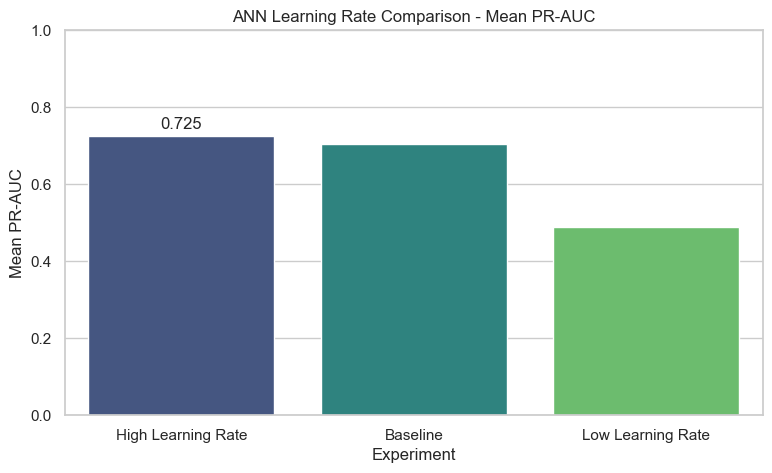

In [93]:
pr_auc_comparison = (
    experiment_df
    .groupby("Experiment")["PR-AUC"]
    .mean()
    .reset_index()
    .sort_values("PR-AUC", ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=pr_auc_comparison,
    x="Experiment",
    y="PR-AUC",
    hue="Experiment",
    palette="viridis",
    legend=False
)

ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

plt.title("ANN Learning Rate Comparison - Mean PR-AUC")
plt.xlabel("Experiment")
plt.ylabel("Mean PR-AUC")
plt.ylim(0, 1)
plt.show()

### Compare recall and F1-score

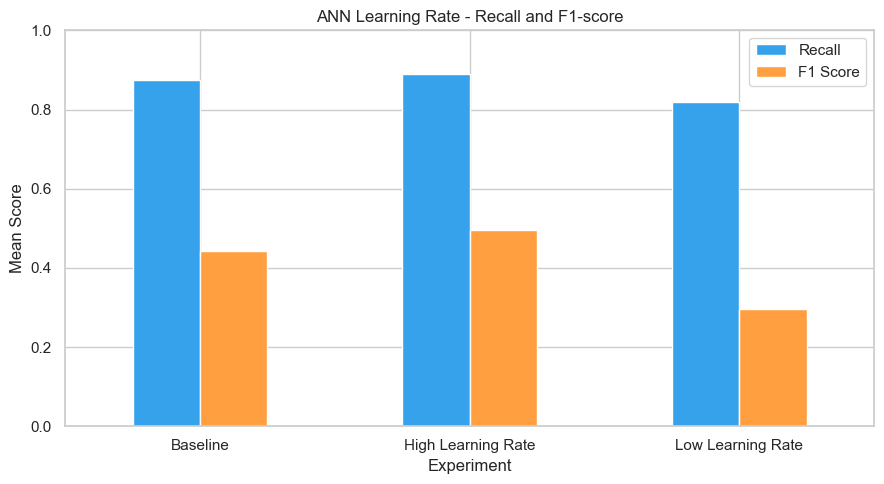

In [94]:
comparison_metrics = (
    experiment_df
    .groupby("Experiment")[["Recall", "F1 Score"]]
    .mean()
    .reset_index()
)

comparison_metrics.plot(
    x="Experiment",
    kind="bar",
    figsize=(9, 5),
    color=["#36A2EB", "#FF9F40"]
)

plt.title("ANN Learning Rate - Recall and F1-score")
plt.ylabel("Mean Score")
plt.xlabel("Experiment")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(["Recall", "F1 Score"])
plt.tight_layout()
plt.show()

### What the recall and F1 chart shows

| Learning rate | Average recall | Average precision | Average F1 |
|---|---|---|---|
| 0.0001 (low) | 0.82 | 0.18 | 0.30 |
| 0.001 (baseline) | 0.87 | 0.30 | 0.44 |
| 0.01 (high) | 0.89 | 0.34 | 0.50 |

**In simple words:**
- All three settings catch most failures (recall 0.82 to 0.89).
- The **low learning rate** gives many more false alarms (precision only 0.18),
  so its F1 is much lower. It would send the team to inspect many healthy machines.
- The **high learning rate** has the best balance (F1 0.50), but the next
  section checks whether this difference is real or just chance.

### Examine variability

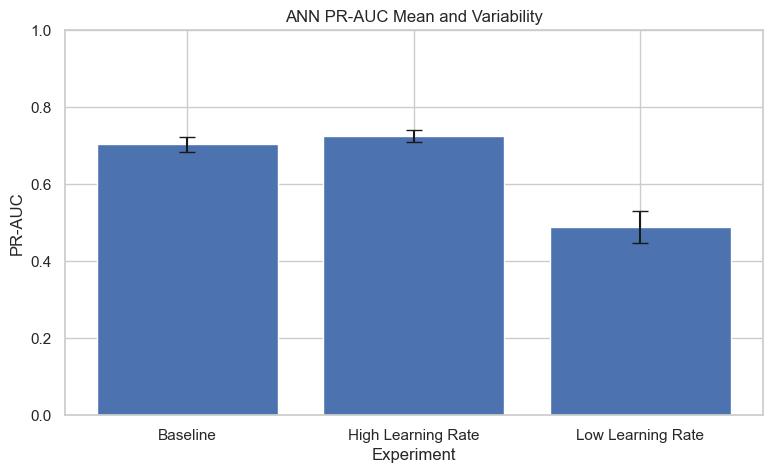

,Experiment,mean,std
0,Baseline,0.7033,0.0201
1,High Learning Rate,0.7255,0.0151
2,Low Learning Rate,0.4888,0.0415


In [95]:
variability = (
    experiment_df
    .groupby("Experiment")["PR-AUC"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    variability["Experiment"],
    variability["mean"],
    yerr=variability["std"],
    capsize=6
)

plt.title("ANN PR-AUC Mean and Variability")
plt.xlabel("Experiment")
plt.ylabel("PR-AUC")
plt.ylim(0, 1)
plt.show()

variability.round(4)

### Identify the best ANN learning rate

In [96]:
best_experiment = (
    experiment_df
    .groupby(["Experiment", "Learning Rate"])["PR-AUC"]
    .mean()
    .reset_index()
    .sort_values("PR-AUC", ascending=False)
    .iloc[0]
)

print("Best ANN Experiment:", best_experiment["Experiment"])
print("Best Learning Rate:", best_experiment["Learning Rate"])
print("Mean Validation PR-AUC:", round(best_experiment["PR-AUC"], 4))

Best ANN Experiment: High Learning Rate
Best Learning Rate: 0.01
Mean Validation PR-AUC: 0.7255


This identifies the best learning rate among the three tested settings. It does not automatically mean that the ANN is better than Random Forest.

### Fair comparison: Random Forest repeated with the same seeds

The ANN was run 5 times, so the tuned Random Forest configuration is also
retrained with the same 5 seeds on the same training data and evaluated on the
same validation set.

In [97]:
best_rf_params = {
    key.replace("model__", ""): value
    for key, value in rf_grid_search.best_params_.items()
}

rf_seed_results = []

for seed in random_seeds:

    rf_seed_model = RandomForestClassifier(
        **best_rf_params,
        class_weight="balanced_subsample",
        random_state=seed,
        n_jobs=-1
    )
    rf_seed_model.fit(X_train_processed, y_train)

    probabilities = rf_seed_model.predict_proba(X_val_processed)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    rf_seed_results.append({
        "Experiment": "Tuned Random Forest",
        "Learning Rate": np.nan,
        "Seed": seed,
        "Epochs": np.nan,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

rf_seed_df = pd.DataFrame(rf_seed_results)

print("Tuned Random Forest parameters:", best_rf_params)
display(rf_seed_df.round(4))
print("Mean PR-AUC:", round(rf_seed_df["PR-AUC"].mean(), 4),
      "| Std:", round(rf_seed_df["PR-AUC"].std(), 4))

Tuned Random Forest parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,Experiment,Learning Rate,Seed,Epochs,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Tuned Random Forest,NaN,42,NaN,0.9231,0.7059,0.8000,0.9880,0.8634
1,Tuned Random Forest,NaN,52,NaN,0.9211,0.6863,0.7865,0.9888,0.8717
2,Tuned Random Forest,NaN,62,NaN,0.9211,0.6863,0.7865,0.9899,0.8756
3,Tuned Random Forest,NaN,72,NaN,0.9231,0.7059,0.8000,0.9889,0.8705
4,Tuned Random Forest,NaN,82,NaN,0.9250,0.7255,0.8132,0.9864,0.8699


Mean PR-AUC: 0.8702 | Std: 0.0044


### Statistical comparison (Welch's t-test and 95% confidence intervals)

,Comparison,Mean A,Mean B,Mean Difference (A - B),95% CI Low,95% CI High,p-value (two-sided),"p-value (one-sided, A > B)",Reliable difference (p < 0.05 and CI excludes 0)
0,ANN lr=0.01 vs ANN lr=0.001,0.7255,0.7033,0.0222,-0.0041,0.0484,0.0865,0.0433,False
1,ANN lr=0.0001 vs ANN lr=0.001,0.4888,0.7033,-0.2145,-0.2654,-0.1636,0.0001,1.0000,True
2,ANN lr=0.001 vs Tuned RF,0.7033,0.8702,-0.1669,-0.1916,-0.1423,0.0000,1.0000,True
3,Best ANN (High Learning Rate) vs Tuned RF,0.7255,0.8702,-0.1447,-0.1632,-0.1262,0.0000,1.0000,True


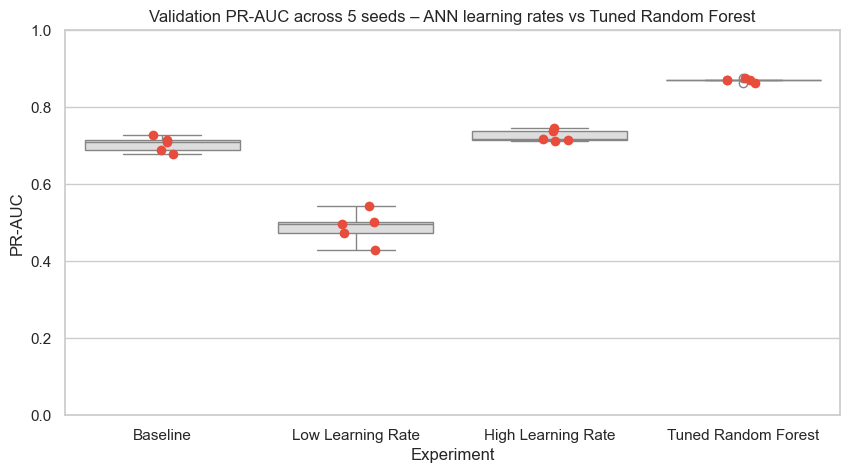

In [98]:
def compare_groups(a, b, label_a, label_b):
    """Welch's t-test and 95% CI for mean(a) - mean(b)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    diff = a.mean() - b.mean()
    var_a, var_b = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(var_a + var_b)

    if se == 0:
        ci_low = ci_high = diff
        p_two = 0.0 if diff != 0 else 1.0
        t_stat = np.nan
    else:
        dof = se ** 4 / (var_a ** 2 / (len(a) - 1) + var_b ** 2 / (len(b) - 1))
        t_crit = stats.t.ppf(0.975, dof)
        ci_low, ci_high = diff - t_crit * se, diff + t_crit * se
        t_stat, p_two = stats.ttest_ind(a, b, equal_var=False)

    # One-sided p-value for H1: mean(a) > mean(b)
    if np.isnan(t_stat):
        p_one = 0.0 if diff > 0 else 1.0
    else:
        p_one = p_two / 2 if t_stat > 0 else 1 - p_two / 2

    return {
        "Comparison": f"{label_a} vs {label_b}",
        f"Mean A": a.mean(),
        f"Mean B": b.mean(),
        "Mean Difference (A - B)": diff,
        "95% CI Low": ci_low,
        "95% CI High": ci_high,
        "p-value (two-sided)": p_two,
        "p-value (one-sided, A > B)": p_one,
        "Reliable difference (p < 0.05 and CI excludes 0)": bool(
            p_two < 0.05 and (ci_low > 0 or ci_high < 0)
        )
    }


def pr_auc_of(experiment):
    return experiment_df.loc[experiment_df["Experiment"] == experiment, "PR-AUC"].values


comparisons = [
    compare_groups(pr_auc_of("High Learning Rate"), pr_auc_of("Baseline"), "ANN lr=0.01", "ANN lr=0.001"),
    compare_groups(pr_auc_of("Low Learning Rate"), pr_auc_of("Baseline"), "ANN lr=0.0001", "ANN lr=0.001"),
    compare_groups(pr_auc_of("Baseline"), rf_seed_df["PR-AUC"].values, "ANN lr=0.001", "Tuned RF"),
    compare_groups(pr_auc_of(best_experiment["Experiment"]), rf_seed_df["PR-AUC"].values,
                   f"Best ANN ({best_experiment['Experiment']})", "Tuned RF"),
]

statistical_comparison_df = pd.DataFrame(comparisons).round(4)
display(statistical_comparison_df)

# Visual: PR-AUC of every run
plot_df = pd.concat([experiment_df[["Experiment", "PR-AUC"]], rf_seed_df[["Experiment", "PR-AUC"]]])
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x="Experiment", y="PR-AUC", color="#DDDDDD")
sns.stripplot(data=plot_df, x="Experiment", y="PR-AUC", color="#E74C3C", size=7)
plt.title("Validation PR-AUC across 5 seeds – ANN learning rates vs Tuned Random Forest")
plt.ylim(0, 1)
plt.show()

### Are the differences real, or just chance?

| Comparison | Difference in PR-AUC | p-value | Verdict |
|---|---|---|---|
| ANN lr 0.01 vs lr 0.001 | +0.022 | 0.087 | **Not a real difference**, could be chance |
| ANN lr 0.0001 vs lr 0.001 | −0.215 | 0.0001 | **Really worse** |
| ANN (lr 0.001) vs Random Forest | −0.167 | < 0.001 | **Random Forest really better** |
| Best ANN (lr 0.01) vs Random Forest | −0.145 | < 0.001 | **Random Forest really better** |

**In simple words:**
- A learning rate that is **too low (0.0001)** clearly hurts. The model did not
  finish learning in 50 epochs.
- **0.01 looks slightly better than 0.001**, but the difference is too small to
  be sure.
- **Random Forest beats every ANN setting**, and it is also much more
  consistent between runs (std 0.004 vs 0.015–0.042 for the ANN).

## Phase 4 – Conclusion

| Setting | Average PR-AUC (5 runs) | Variation (std) | Average epochs |
|---|---|---|---|
| Low learning rate (0.0001) | 0.489 | 0.042 | 50.0 |
| Baseline (0.001) | 0.703 | 0.020 | 39.8 |
| High learning rate (0.01) | 0.726 | 0.015 | 33.0 |
| Tuned Random Forest (for comparison) | **0.870** | **0.004** | – |



## Phase 5 – Business Interpretation

###  Failure Risk Categorization

The selected model's predicted failure probability is used to place each
**record** into one of three risk bands. A record is one machine operating
snapshot; the dataset is not tracked per physical machine. The band limits are
tied to the validation-selected threshold:

- **Low Risk:** probability below the selected alert threshold, so no alert is raised.
- **Medium Risk:** from the alert threshold up to the High Risk cut-off.
- **High Risk:** probability of 0.5 or above (or at least 0.10 above the alert
  threshold, if that is higher), meaning most of the model agrees on a failure.


In [99]:
low_cut = float(best_threshold)
high_cut = max(0.5, low_cut + 0.10)

print(f"Low Risk    : probability < {low_cut:.2f}")
print(f"Medium Risk : {low_cut:.2f} <= probability < {high_cut:.2f}")
print(f"High Risk   : probability >= {high_cut:.2f}")

# Create a copy of the test data with identifiers for traceability
risk_results = X_test.copy()
risk_results.insert(0, "Product ID", df.loc[X_test.index, "Product ID"].values)
risk_results.insert(0, "UDI", df.loc[X_test.index, "UDI"].values)

risk_results["Actual Failure"] = y_test.values
risk_results["Failure Probability"] = test_probabilities

risk_results["Risk Category"] = pd.cut(
    risk_results["Failure Probability"],
    bins=[-0.000001, low_cut, high_cut, 1.000001],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    right=False
)

print("\nFailure Risk Categorization (first 10 test records)")

display(
    risk_results[[
        "UDI",
        "Failure Probability",
        "Risk Category",
        "Actual Failure"
    ]].head(10).reset_index(drop=True)
)

Low Risk    : probability < 0.15
Medium Risk : 0.15 <= probability < 0.50
High Risk   : probability >= 0.50

Failure Risk Categorization (first 10 test records)


,UDI,Failure Probability,Risk Category,Actual Failure
0,1530,0.000546,Low Risk,0
1,8573,0.000434,Low Risk,0
2,4331,0.007369,Low Risk,0
3,1503,0.039683,Low Risk,0
4,9356,0.002978,Low Risk,0
5,7940,0.209014,Medium Risk,0
6,2397,0.004529,Low Risk,0
7,3786,0.001456,Low Risk,0
8,8885,0.000318,Low Risk,0
9,5657,0.060984,Low Risk,0


### Count records in each risk category

### Distribution of Risk Categories

This analysis shows how many test records fall into the low, medium and high
risk categories, which gives an estimate of the maintenance team's inspection
workload.

Risk Category
Low Risk       1379
Medium Risk      78
High Risk        43
Name: count, dtype: int64


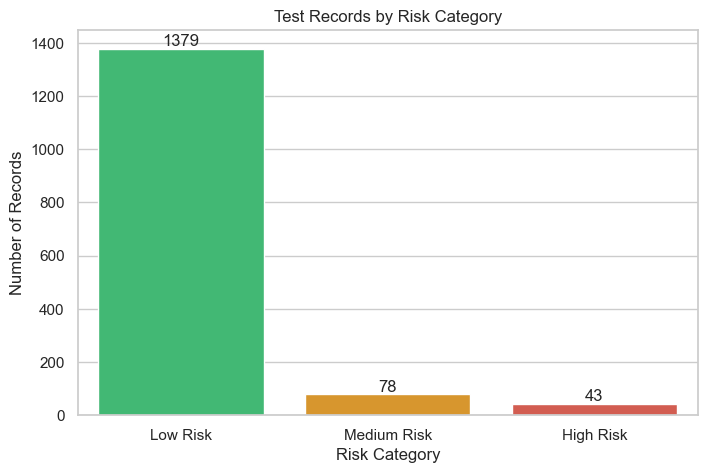

In [100]:
risk_counts = risk_results["Risk Category"].value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
)

print(risk_counts)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values,
    hue=risk_counts.index,
    palette=["#2ecc71", "#f39c12", "#e74c3c"],
    legend=False
)

plt.title("Test Records by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Do the risk bands make sense? Observed failure rate per band (test set)

In [101]:
band_summary = risk_results.groupby("Risk Category", observed=False).agg(
    Records=("Actual Failure", "size"),
    Actual_Failures=("Actual Failure", "sum"),
    Mean_Predicted_Probability=("Failure Probability", "mean")
)

band_summary["Observed Failure Rate (%)"] = (
    band_summary["Actual_Failures"] / band_summary["Records"] * 100
)
band_summary["Share of All Failures (%)"] = (
    band_summary["Actual_Failures"] / band_summary["Actual_Failures"].sum() * 100
)

display(band_summary.round(3))

,Records,Actual_Failures,Mean_Predicted_Probability,Observed Failure Rate (%),Share of All Failures (%)
Risk Category,,,,,
Low Risk,1379,4,0.012,0.290,7.843
Medium Risk,78,6,0.258,7.692,11.765
High Risk,43,41,0.763,95.349,80.392


### Do the risk groups make sense? (test set)

| Risk group | Records | Real failures | Failure rate | Share of all failures |
|---|---|---|---|---|
| Low (below 0.15) | 1,379 | 4 | **0.29%** | 7.8% |
| Medium (0.15 – 0.50) | 78 | 6 | **7.7%** | 11.8% |
| High (0.50 and above) | 43 | 41 | **95.3%** | 80.4% |


- **High risk:** almost every record (95%) really failed, so act **immediately**.
- **Medium risk:** about twice the normal failure rate, so **plan an inspection** soon.
- **Low risk:** very safe (0.29%), so **normal routine maintenance**.
- By inspecting only the High and Medium records (121 of 1,500, about 8%), we
  would catch **47 of 51 failures**.

### Prioritized inspection queue

Test records sorted by predicted failure probability. The maintenance team works
from the top of this list down, as far as its daily inspection capacity allows.

In [102]:
inspection_queue = (
    risk_results
    .sort_values("Failure Probability", ascending=False)
    .reset_index(drop=True)
)
inspection_queue.insert(0, "Priority Rank", range(1, len(inspection_queue) + 1))

queue_columns = [
    "Priority Rank", "UDI", "Product ID", "Type", "Failure Probability",
    "Risk Category", "Torque [Nm]", "Rotational speed [rpm]",
    "Tool wear [min]", "Power [W]", "Temperature difference [K]", "Actual Failure"
]

display(inspection_queue[queue_columns].head(20).round(3))

# How many failures are caught if only the top-N records can be inspected?
capacity_rows = []
for top_n in [25, 50, 75, 100, 150, 200]:
    caught = inspection_queue.head(top_n)["Actual Failure"].sum()
    capacity_rows.append({
        "Inspections Available (top N)": top_n,
        "Failures Caught": caught,
        "Share of Test Failures Caught (%)": round(caught / inspection_queue["Actual Failure"].sum() * 100, 1)
    })
display(pd.DataFrame(capacity_rows))

,Priority Rank,UDI,Product ID,Type,Failure Probability,Risk Category,Torque [Nm],Rotational speed [rpm],Tool wear [min],Power [W],Temperature difference [K],Actual Failure
0,1,8399,L55578,L,0.966,High Risk,12.1,2617,102,3316.024,11.2,1
1,2,1392,L48571,L,0.950,High Risk,8.8,2737,142,2522.238,11.3,1
2,3,4730,L51909,L,0.946,High Risk,61.0,1306,215,8342.604,8.4,1
3,4,6079,L53258,L,0.942,High Risk,59.1,1339,203,8286.987,9.9,1
4,5,4571,L51750,L,0.934,High Risk,52.2,1312,40,7171.879,8.1,1
5,6,4566,H33979,H,0.921,High Risk,55.0,1275,25,7343.473,8.1,1
6,7,6800,M21659,M,0.920,High Risk,12.2,2636,100,3367.704,9.6,1
7,8,4271,L51450,L,0.914,High Risk,52.0,1331,154,7247.864,8.3,1
8,9,7998,M22857,M,0.910,High Risk,9.7,2710,143,2752.768,11.2,1
9,10,9665,L56844,L,0.904,High Risk,54.8,1317,231,7557.792,11.1,1


,Inspections Available (top N),Failures Caught,Share of Test Failures Caught (%)
0,25,25,49.0
1,50,42,82.4
2,75,44,86.3
3,100,45,88.2
4,150,47,92.2
5,200,49,96.1


### How useful is the inspection list?

If the team inspects records in order, from highest risk to lowest:

| Inspections done | Failures caught |
|---|---|
| Top 25 | 25 of 51 (**all 25 were real failures**) |
| Top 50 | 42 of 51 (82%) |
| Top 100 | 45 of 51 (88%) |
| Top 200 | 49 of 51 (96%) |


### Important Sensor Patterns

Sensor readings such as air temperature, process temperature,
rotational speed, torque, and tool wear can provide useful information
about machine operating conditions.

We will examine the relationship between sensor readings and actual
machine failures to identify patterns that may help maintenance teams.

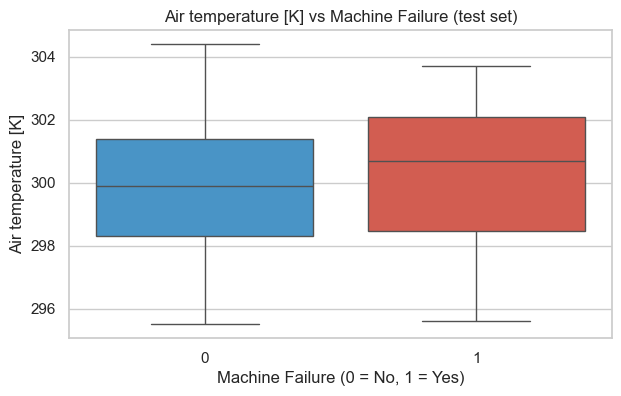

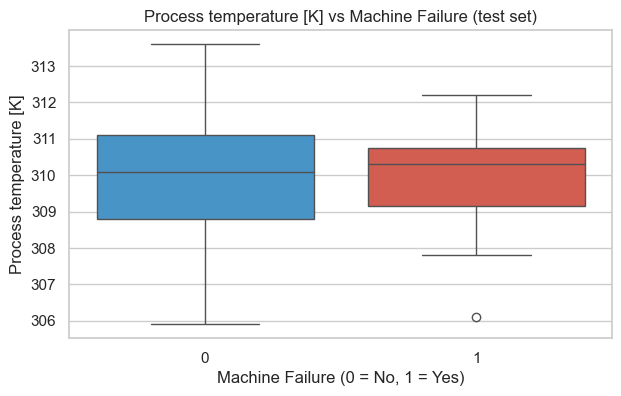

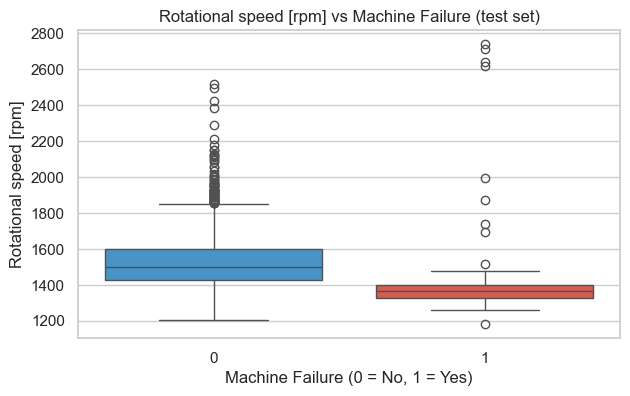

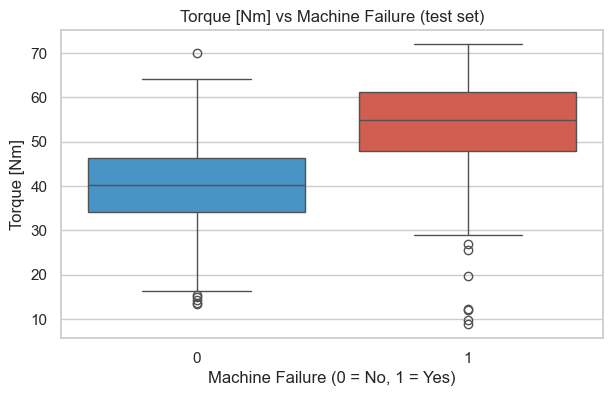

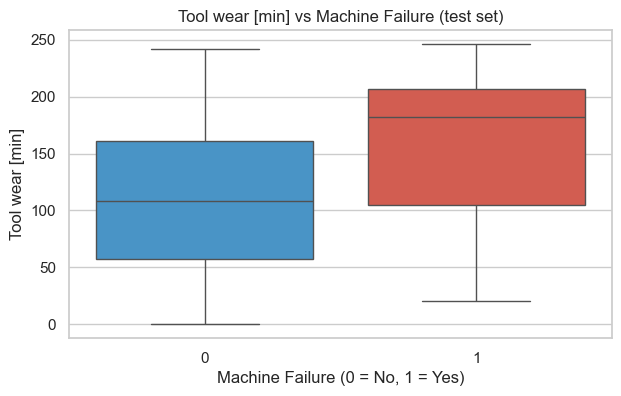

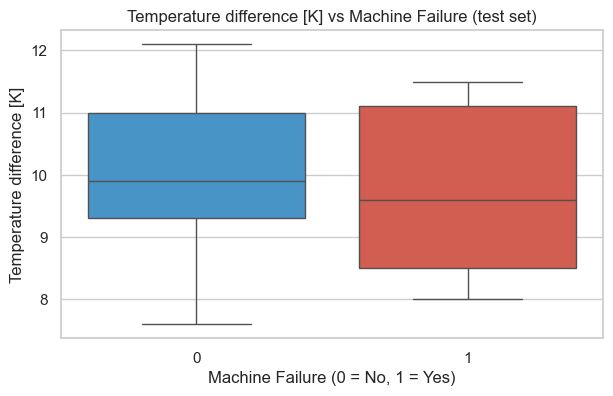

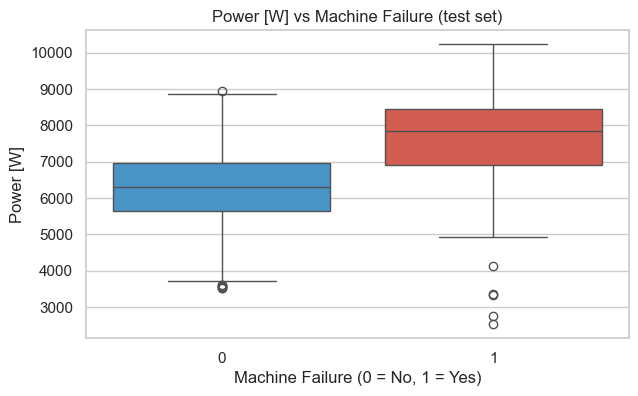

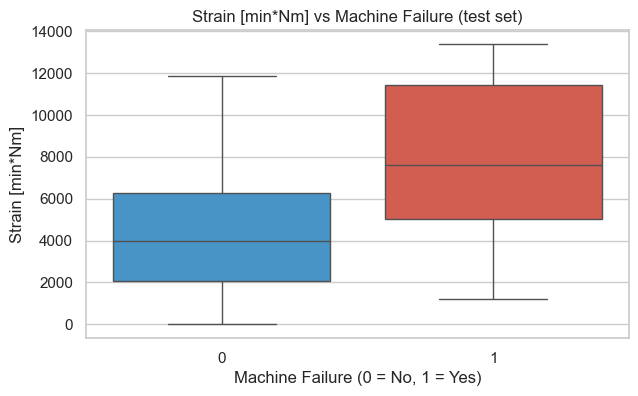

In [103]:
sensor_data = X_test.copy()
sensor_data["Machine Failure"] = y_test.values

pattern_columns = sensor_columns + engineered_features

for column in pattern_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=sensor_data,
        x="Machine Failure",
        y=column,
        hue="Machine Failure",
        palette=["#3498db", "#e74c3c"],
        legend=False
    )

    plt.title(f"{column} vs Machine Failure (test set)")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(column)

    plt.show()

### Sensor patterns on the test set

| Feature | Normal (median) | Failed (median) | What we see |
|---|---|---|---|
| Torque | 40.3 Nm | 55.0 Nm | Failed machines work under **more load** |
| Rotational speed | 1500 rpm | 1363 rpm | Failed machines often run **slower** |
| Tool wear | 108 min | 182 min | Failed machines have **more worn tools** |
| Power | 6,310 W | 7,839 W | Failures happen at **too high or too low** power |
| Strain | 3,966 | 7,615 | Almost **double** for failures, the clearest sign |
| Temperature difference | 9.9 K | 9.6 K | Failures happen more when **cooling is poor** |
| Air / process temperature | 299.9 / 310.1 K | 300.7 / 310.3 K | Very small difference |

These patterns match what we found on the full dataset in Phase 1, so they are
consistent.



### Feature Importance Analysis

We use two methods:

1. **Impurity-based importance** from the Random Forest. It is fast, but it is
   biased towards continuous features with many split points.
2. **Permutation importance** on the **test set** for the selected model: how
   much the test PR-AUC drops when one feature is randomly shuffled. This is
   model-agnostic and measured on unseen data.

Both show which inputs the *model relies on*. They do not show what *causes*
failures. Correlated features (for example torque, power and strain) share
their importance, so the ranking among them should be read with care.

,Feature,Impurity Importance (RF)
2,num__Rotational speed [rpm],0.2112
3,num__Torque [Nm],0.1853
6,num__Power [W],0.1777
4,num__Tool wear [min],0.1373
7,num__Strain [min*Nm],0.1129
5,num__Temperature difference [K],0.0842
0,num__Air temperature [K],0.0487
1,num__Process temperature [K],0.0305
10,cat__Type_M,0.0051
9,cat__Type_L,0.0047


Permutation importance for Tuned Random Forest (test PR-AUC = 0.8916)


,Feature,Mean PR-AUC Drop,Std PR-AUC Drop
3,Rotational speed [rpm],0.3010,0.0601
6,Temperature difference [K],0.2212,0.0176
7,Power [W],0.1754,0.0102
8,Strain [min*Nm],0.1530,0.0113
0,Type,0.0813,0.0333
4,Torque [Nm],0.0797,0.0095
1,Air temperature [K],0.0260,0.0047
5,Tool wear [min],0.0196,0.0083
2,Process temperature [K],-0.0060,0.0045


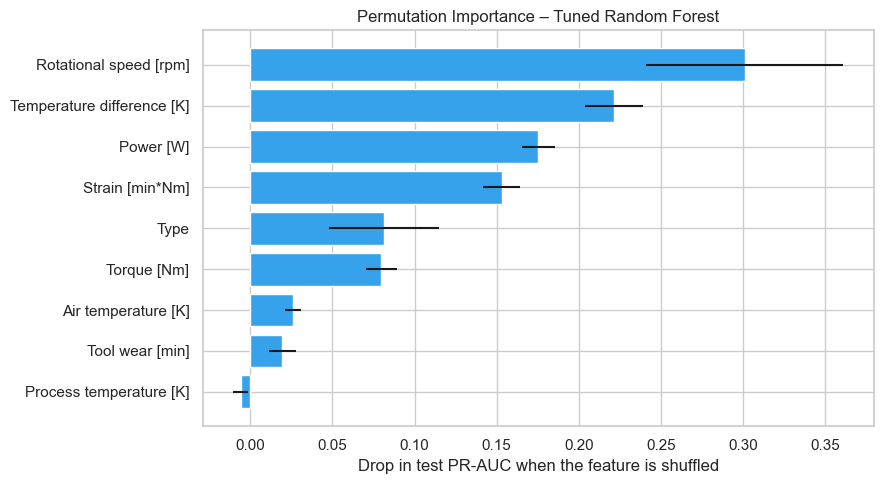

In [104]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Impurity Importance (RF)": rf_model.feature_importances_
}).sort_values(by="Impurity Importance (RF)", ascending=False)

display(feature_importance.round(4))


def permutation_importance_pr_auc(predict_fn, X_raw, y_true, n_repeats=10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    baseline_score = average_precision_score(y_true, predict_fn(X_raw))
    rows = []
    for column in X_raw.columns:
        drops = []
        for _ in range(n_repeats):
            X_permuted = X_raw.copy()
            X_permuted[column] = rng.permutation(X_permuted[column].values)
            drops.append(baseline_score - average_precision_score(y_true, predict_fn(X_permuted)))
        rows.append({
            "Feature": column,
            "Mean PR-AUC Drop": np.mean(drops),
            "Std PR-AUC Drop": np.std(drops)
        })
    return baseline_score, pd.DataFrame(rows).sort_values("Mean PR-AUC Drop", ascending=False)


baseline_pr_auc, permutation_df = permutation_importance_pr_auc(
    model_predictors[selected_model_name], X_test, y_test_actual
)

print(f"Permutation importance for {selected_model_name} (test PR-AUC = {baseline_pr_auc:.4f})")
display(permutation_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(permutation_df["Feature"], permutation_df["Mean PR-AUC Drop"],
         xerr=permutation_df["Std PR-AUC Drop"], color="#36A2EB")
plt.gca().invert_yaxis()
plt.xlabel("Drop in test PR-AUC when the feature is shuffled")
plt.title(f"Permutation Importance – {selected_model_name}")
plt.tight_layout()
plt.show()

### Which features matter most?

**Random Forest's own ranking (impurity importance):**
rotational speed (0.21) > torque (0.19) > power (0.18) > tool wear (0.14) >
strain (0.11). Product type matters very little.

**Shuffle test on new data (permutation importance):**
we randomly mixed up one feature at a time and measured how much worse the
model got.

| Feature | Drop in PR-AUC when mixed up |
|---|---|
| Rotational speed | 0.30 (biggest) |
| Temperature difference | 0.22 |
| Power | 0.18 |
| Strain | 0.15 |
| Process temperature | about 0 (not needed) |

- **Rotational speed is the most important input.**
- **3 of the top 4 are our new engineered features**, so feature engineering
  was worth it.
- Torque and tool wear look less important here only because power and strain
  already contain their information.

**Recommendation:** monitor **speed, torque, power, tool wear, strain and the
temperature difference** most closely.

### Prioritized Maintenance Recommendations

Based on the predicted machine failure risk, the maintenance team
can prioritize inspections and maintenance activities.

| Risk Category | Priority | Recommended Action |
|---|---|---|
| Low Risk | Routine | Continue normal operation and scheduled maintenance. |
| Medium Risk | Moderate | Schedule an inspection and monitor sensor readings regularly. |
| High Risk | Urgent | Prioritize inspection and perform maintenance checks as soon as possible. |

The model should support maintenance decisions rather than automatically
shutting down machines.

In [105]:
# Build results/model_comparison.csv from the computed results (no hard-coded numbers)

os.makedirs(RESULTS_DIR, exist_ok=True)


def metric_row(model_name, evaluation_set, y_true, probs, threshold, threshold_type):
    preds = (probs >= threshold).astype(int)
    tn, fp_, fn_, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        "Model": model_name,
        "Evaluation_Set": evaluation_set,
        "Threshold_Type": threshold_type,
        "Decision_Threshold": threshold,
        "Accuracy": accuracy_score(y_true, preds),
        "Precision": precision_score(y_true, preds, zero_division=0),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "F1_Score": f1_score(y_true, preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probs),
        "PR_AUC": average_precision_score(y_true, probs),
        "TN": tn, "FP": fp_, "FN": fn_, "TP": tp,
        "Hypothetical_Cost_INR": fp_ * cost_per_false_positive + fn_ * cost_per_false_negative,
        "Selected_Model": model_name == selected_model_name
    }


export_rows = []

for name in model_predictors:
    cost_threshold = best_threshold_lookup[name]
    export_rows.append(metric_row(name, "Train", y_train_actual, train_probabilities[name], 0.5, "Default"))
    export_rows.append(metric_row(name, "Validation", y_val_actual, validation_probabilities[name], 0.5, "Default"))
    export_rows.append(metric_row(name, "Validation", y_val_actual, validation_probabilities[name], cost_threshold, "Validation cost-optimal"))
    export_rows.append(metric_row(name, "Test (after selection)", y_test_actual, test_probabilities_all[name], 0.5, "Default"))
    export_rows.append(metric_row(name, "Test (after selection)", y_test_actual, test_probabilities_all[name], cost_threshold, "Validation cost-optimal"))

model_comparison_export = pd.DataFrame(export_rows).round(4)

model_comparison_export.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)

print("Saved results/model_comparison.csv")
print("Cost assumptions: FP = ₹", cost_per_false_positive, "| FN = ₹", cost_per_false_negative)
display(model_comparison_export)

Saved results/model_comparison.csv
Cost assumptions: FP = ₹ 2000 | FN = ₹ 50000


,Model,Evaluation_Set,Threshold_Type,Decision_Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TN,FP,FN,TP,Hypothetical_Cost_INR,Selected_Model
0,Logistic Regression,Train,Default,0.50,0.8540,0.1715,0.8650,0.2863,0.9339,0.4741,5773,990,32,205,3580000,False
1,Logistic Regression,Validation,Default,0.50,0.8620,0.1695,0.7843,0.2787,0.9048,0.3561,1253,196,11,40,942000,False
2,Logistic Regression,Validation,Validation cost-optimal,0.45,0.8420,0.1556,0.8235,0.2617,0.9048,0.3561,1221,228,9,42,906000,False
3,Logistic Regression,Test (after selection),Default,0.50,0.8613,0.1796,0.8627,0.2973,0.9372,0.4432,1248,201,7,44,752000,False
4,Logistic Regression,Test (after selection),Validation cost-optimal,0.45,0.8347,0.1568,0.8824,0.2663,0.9372,0.4432,1207,242,6,45,784000,False
5,Tuned Logistic Regression,Train,Default,0.50,0.8483,0.1633,0.8439,0.2736,0.9273,0.5053,5738,1025,37,200,3900000,False
6,Tuned Logistic Regression,Validation,Default,0.50,0.8647,0.1696,0.7647,0.2776,0.9008,0.3927,1258,191,12,39,982000,False
7,Tuned Logistic Regression,Validation,Validation cost-optimal,0.40,0.8007,0.1310,0.8627,0.2274,0.9008,0.3927,1157,292,7,44,934000,False
8,Tuned Logistic Regression,Test (after selection),Default,0.50,0.8453,0.1685,0.9020,0.2840,0.9275,0.4540,1222,227,5,46,704000,False
9,Tuned Logistic Regression,Test (after selection),Validation cost-optimal,0.40,0.7813,0.1247,0.9020,0.2190,0.9275,0.4540,1126,323,5,46,896000,False


In [106]:
# Build results/experiment_results.csv: one row per run, with every setting and seed

ann_runs = experiment_df.rename(columns={"Epochs": "Epochs_Run"}).copy()
ann_runs["Model"] = "ANN"
ann_runs["Optimizer"] = "Adam"
ann_runs["Architecture"] = f"Input({X_train_processed.shape[1]}) - Dense(64, relu) - Dropout(0.30) - Dense(32, relu) - Dropout(0.20) - Dense(1, sigmoid)"
ann_runs["Loss"] = "binary_crossentropy"
ann_runs["Batch_Size"] = 32
ann_runs["Maximum_Epochs"] = 50
ann_runs["Callbacks"] = "EarlyStopping(val_loss, patience=8, restore_best_weights=True); ReduceLROnPlateau(val_loss, factor=0.5, patience=4, min_lr=1e-5)"

rf_runs = rf_seed_df.rename(columns={"Epochs": "Epochs_Run"}).copy()
rf_runs["Model"] = "Random Forest"
rf_runs["Optimizer"] = "n/a"
rf_runs["Architecture"] = f"RandomForestClassifier({best_rf_params})"
rf_runs["Loss"] = "gini"
rf_runs["Batch_Size"] = np.nan
rf_runs["Maximum_Epochs"] = np.nan
rf_runs["Callbacks"] = "n/a"

experiment_export = pd.concat([ann_runs, rf_runs], ignore_index=True)
experiment_export["Changed_Factor"] = np.where(
    experiment_export["Model"] == "ANN", "Initial learning rate", "None (seed repeat for fair comparison)"
)
experiment_export["Class_Weighting"] = "balanced (training data only)"
experiment_export["Features"] = ", ".join(X_train.columns)
experiment_export["Evaluation_Set"] = "Validation"
experiment_export["Decision_Threshold"] = 0.5

experiment_export = experiment_export[[
    "Model", "Experiment", "Changed_Factor", "Learning Rate", "Seed", "Epochs_Run",
    "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC",
    "Optimizer", "Architecture", "Loss", "Batch_Size", "Maximum_Epochs", "Callbacks",
    "Class_Weighting", "Features", "Evaluation_Set", "Decision_Threshold"
]].round(4)

experiment_export.to_csv(RESULTS_DIR / "experiment_results.csv", index=False)

# Summary (mean, std, n) per experiment
experiment_summary_export = (
    experiment_export.groupby(["Model", "Experiment", "Learning Rate"], dropna=False)
    .agg(Number_of_Runs=("PR-AUC", "size"),
         Mean_PR_AUC=("PR-AUC", "mean"), Std_PR_AUC=("PR-AUC", "std"),
         Mean_ROC_AUC=("ROC-AUC", "mean"), Std_ROC_AUC=("ROC-AUC", "std"),
         Mean_Recall=("Recall", "mean"), Std_Recall=("Recall", "std"),
         Mean_F1=("F1 Score", "mean"), Std_F1=("F1 Score", "std"))
    .reset_index()
    .round(4)
)
experiment_summary_export.to_csv(RESULTS_DIR / "experiment_summary.csv", index=False)
statistical_comparison_df.to_csv(RESULTS_DIR / "statistical_comparison.csv", index=False)

print("Saved results/experiment_results.csv, results/experiment_summary.csv, results/statistical_comparison.csv")
display(experiment_summary_export)

Saved results/experiment_results.csv, results/experiment_summary.csv, results/statistical_comparison.csv


,Model,Experiment,Learning Rate,Number_of_Runs,Mean_PR_AUC,Std_PR_AUC,Mean_ROC_AUC,Std_ROC_AUC,Mean_Recall,Std_Recall,Mean_F1,Std_F1
0,ANN,Baseline,0.0010,5,0.7033,0.0201,0.9729,0.0030,0.8745,0.0108,0.4433,0.0034
1,ANN,High Learning Rate,0.0100,5,0.7255,0.0151,0.9756,0.0046,0.8902,0.0407,0.4958,0.0290
2,ANN,Low Learning Rate,0.0001,5,0.4888,0.0415,0.9319,0.0132,0.8196,0.0164,0.2950,0.0318
3,Random Forest,Tuned Random Forest,NaN,5,0.8702,0.0044,0.9884,0.0013,0.7020,0.0164,0.7972,0.0112


## Limitations

1. **Synthetic data:** the dataset is computer-generated, so real machines may
   behave differently.
2. **No time history:** each record is a single snapshot, so the model cannot
   see trends such as temperature rising over hours.
3. **Very few failures:** only 51 failures each in the validation and test sets.
   Missing just 1 failure changes recall by about 2%.
4. **Label problems:** 27 records have labels that do not agree (see Phase 1).
   Random failures (RNF) cannot be predicted from the sensors at all.
5. **Validation set used many times:** it was used for early stopping, model
   choice and threshold choice, so validation scores look a little better than
   reality. The test set gives the honest result.
6. **Costs are assumed:** ₹2,000 and ₹50,000 are examples, not real company
   figures. The best threshold changes if the costs change.
7. **Random Forest memorises the training data:** it may get worse if machine
   conditions change over time.
8. **Links, not causes:** feature importance does not prove that a sensor
   causes failure.
9. **Probabilities are scores, not exact chances:** a score of 0.15 does not
   mean exactly a 15% chance of failure.

### Next steps
- Test the model on **real factory data**, using older data for training and
  newer data for testing.
- Get the **real costs** from the maintenance team and set the threshold again.
- Try other models (for example Random Forest without class weights, or gradient boosting).
- **Keep monitoring** the model after deployment and retrain it regularly.

## Final Business Conclusion

**1. Can we build a good failure prediction model?**
**Yes.** The Random Forest caught **47 of 51 failures (92%)** on data it had
never seen. Only 74 of 1,449 healthy records got an unnecessary inspection.

**2. How reliable are the models, and what do mistakes cost?**
With our assumed costs (₹2,000 per false alarm, ₹50,000 per missed failure):

| Model | Test cost |
|---|---|
| **Random Forest (threshold 0.15)** | **₹3,48,000** (cheapest) |
| ANN | ₹4,96,000 |
| Logistic Regression | ₹7–9 lakh |

Random Forest stays the best choice even if the costs change.

**3. Is the ANN better than traditional ML?**
**No.** Over 5 runs, the ANN averaged 0.726 PR-AUC vs 0.870 for Random Forest.
That difference is real, not chance (p < 0.001), and the ANN results also
varied more between runs.

### What the maintenance team should do

| Risk level | Action |
|---|---|
| **High** (0.50 and above) | Inspect **immediately**: 95% of these really failed |
| **Medium** (0.15 – 0.50) | **Plan an inspection** in the next maintenance window |
| **Low** (below 0.15) | Continue **normal routine maintenance**: only 0.29% failed |

- If inspection time is limited, work **from the top of the risk list**. The
  top 50 records contained 82% of all failures.
- Watch **speed, torque, power, tool wear, strain and the temperature
  difference** most closely.

### Important
The model should **help** the maintenance team make decisions. It should **not**
shut down machines automatically. Before real use, it must be tested on real
factory data, with real costs, and checked regularly by experts.